In [1]:
# INICIALIZAÇÃO DAS BIBLIOTECAS
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

In [2]:
def set_rho(ff):
    rho_fat = np.array(0.5)
    rho_water = np.array((rho_fat*((1-ff)/ff)))
    return (rho_fat,rho_water)

def discrete_timeseries(n_echoes):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T (TEs adjusted for 3T).
    This is based on studies by Hamilton and Yokoo.
    parameters: n_echoes     -> integer >0, number of equally spaced echoes
    returns:    echo_times
     '''
    
    #TE acquisition times for n echoes
    echo_times = np.linspace(0.0011515, 0.0011515*n_echoes, n_echoes, endpoint=True)
    
    return echo_times

print(discrete_timeseries.__doc__)

def gen_GRE(echo_times, rho_fat, rho_water):
    '''
    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T (TEs adjusted for 3T).
    This is based on studies by Hamilton and Yokoo.
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
    returns:    Sabs (absolute signal intensity) (equivalent to ydata)
    '''
    rho = np.array([rho_fat*0.047,\
    rho_fat*0.039,\
    rho_fat*0.006,\
    rho_fat*0.12,\
    rho_fat*0.7,\
    rho_fat*0.088,\
    rho_water]) #rho_fat is a general variable that multiplies intrinsic fat constants (Hamilton)
    
    #standard, individual T2* values
    t2star = np.array([0.030,\
              0.040,\
              0.051,\
              0.052,\
              0.062,\
              0.083,\
              0.023] )
    
    #frequency in parts per million for each moiety
    freq_ppm = np.array([5.3,\
             4.2,\
             2.75,\
             2.1,\
             1.3,\
             0.9,\
             4.7])

    freq = np.zeros(len(freq_ppm))
    magField = np.array(3.0)      #magnetic field, Tesla (if change, remember to change echo spacing)
    hydroGyro = np.array(42.57e6) #Hydrogen gyromagnetic ratio, Hz/T
    
    for n, fppm in enumerate(freq_ppm):
        freq[n] = fppm*magField*hydroGyro/1e6
    
    #calculate the complex signal for each moiety    
    S = (len(freq_ppm),len(echo_times))
    S = np.zeros(S,dtype='complex')
    
    for n, moieties in enumerate(freq_ppm):
        for t,TE in enumerate(echo_times):
            S[n,t] = rho[n]*np.exp(-TE/t2star[n])*np.exp(2.0*np.pi*1j*freq[n]*TE)         
    
    #obtain sum & absolute value
    Sabs= (len(echo_times))
    Sabs=np.zeros(Sabs,dtype='complex')
    
    Sabs = np.sum(S, axis=0)
    Sabs = np.absolute(Sabs)
    return (Sabs)

print(gen_GRE.__doc__)

def continuous_timeseries(endpoint=0.01):
    return np.linspace(0, endpoint, 1000, endpoint=True)

def calc_fatfrac(fitted_parameters):
    ff =  fitted_parameters[0] / (fitted_parameters[0] + fitted_parameters[1])
    return ff


    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T (TEs adjusted for 3T).
    This is based on studies by Hamilton and Yokoo.
    parameters: n_echoes     -> integer >0, number of equally spaced echoes
    returns:    echo_times
     

    This function calculates the GRE IP-OP signal from human liver, for any number of TEs,
    considering a low flip angle (Taylor approx. around zero) and 3T (TEs adjusted for 3T).
    This is based on studies by Hamilton and Yokoo.
    parameters: echo times -> array with TEs
                rho_fat    -> float >0, fat proton density
                rho_water  -> float >0, water proton density
    returns:    Sabs (absolute signal intensity) (equivalent to ydata)
    


parametro dado:
0.01
paramatro encontrado:
0.01


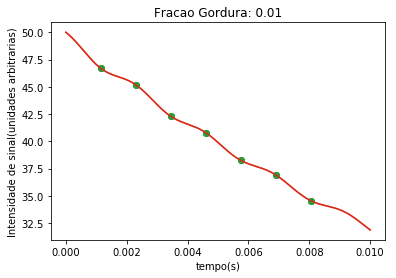

parametro dado:
0.03
paramatro encontrado:
0.03


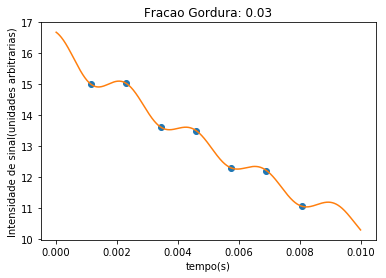

parametro dado:
0.05
paramatro encontrado:
0.05


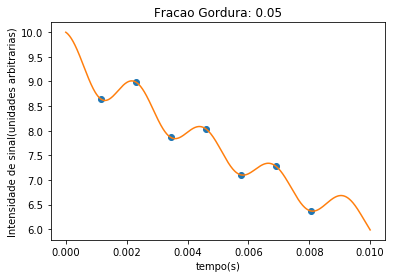

parametro dado:
0.07
paramatro encontrado:
0.07


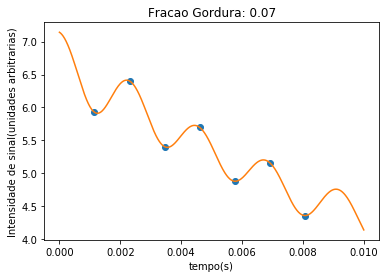

parametro dado:
0.09
paramatro encontrado:
0.09


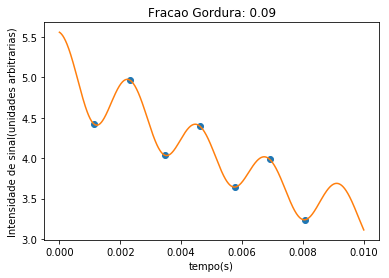

parametro dado:
0.11
paramatro encontrado:
0.11


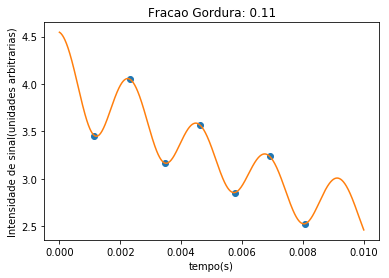

parametro dado:
0.13
paramatro encontrado:
0.13


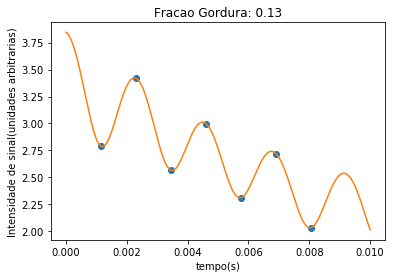

parametro dado:
0.15
paramatro encontrado:
0.15


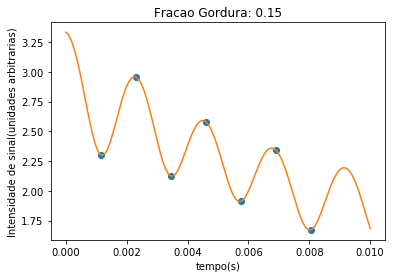

parametro dado:
0.17
paramatro encontrado:
0.17


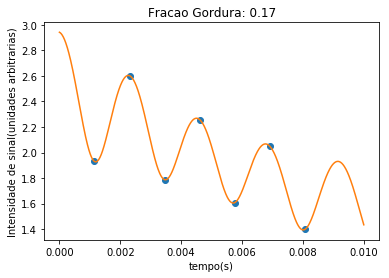

parametro dado:
0.19
paramatro encontrado:
0.19


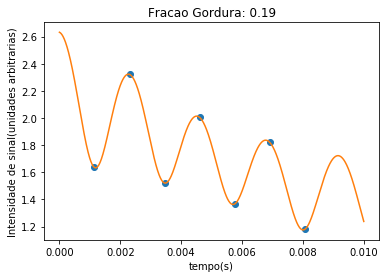

parametro dado:
0.21
paramatro encontrado:
0.21


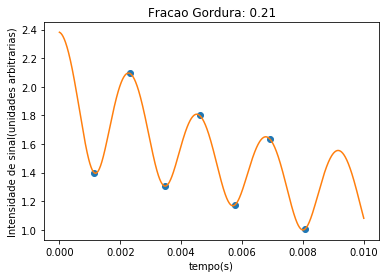

parametro dado:
0.23
paramatro encontrado:
0.23


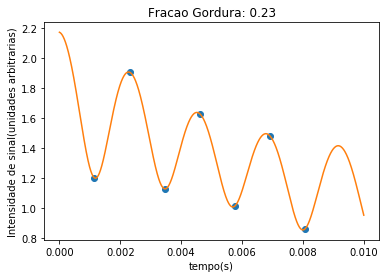

parametro dado:
0.25
paramatro encontrado:
0.25


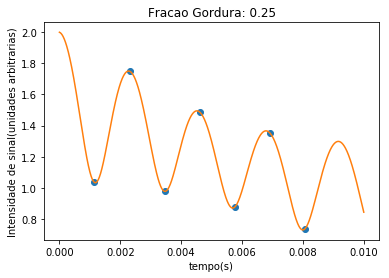

parametro dado:
0.27
paramatro encontrado:
0.27


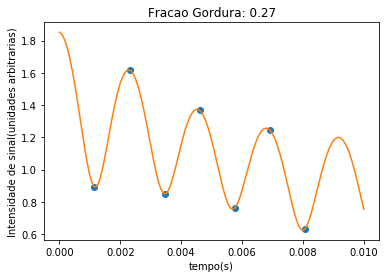

parametro dado:
0.29
paramatro encontrado:
0.29


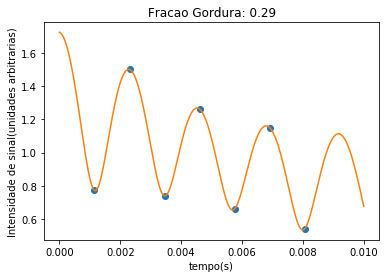

parametro dado:
0.31
paramatro encontrado:
0.31


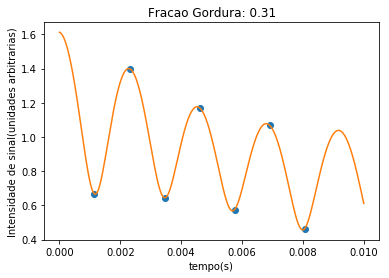

parametro dado:
0.33
paramatro encontrado:
0.33


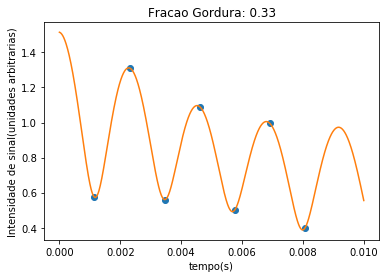

parametro dado:
0.35
paramatro encontrado:
0.35


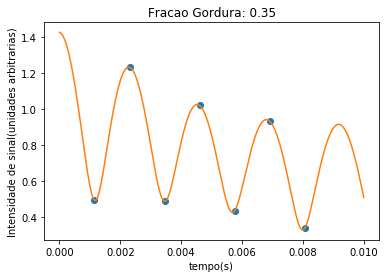

parametro dado:
0.37
paramatro encontrado:
0.37


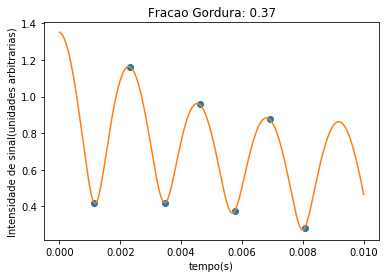

parametro dado:
0.39
paramatro encontrado:
0.39


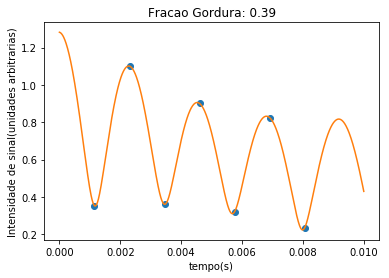

parametro dado:
0.41
paramatro encontrado:
0.41


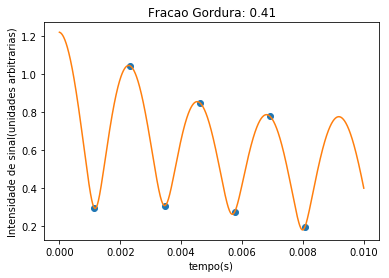

parametro dado:
0.43
paramatro encontrado:
0.43


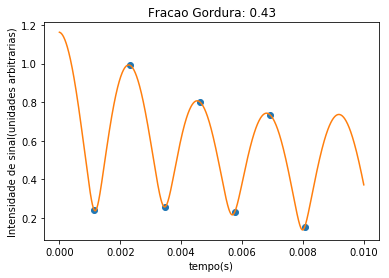

parametro dado:
0.45
paramatro encontrado:
0.45


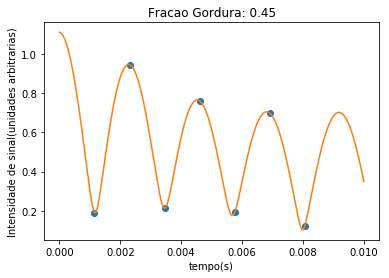

parametro dado:
0.47
paramatro encontrado:
0.47


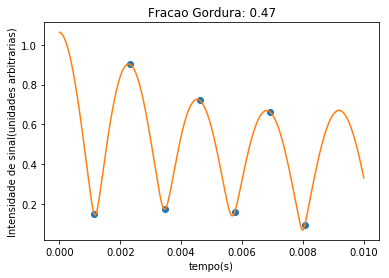

parametro dado:
0.49
paramatro encontrado:
0.49


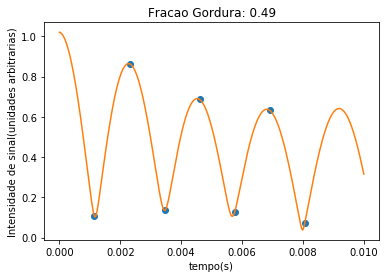

parametro dado:
0.51
paramatro encontrado:
0.51


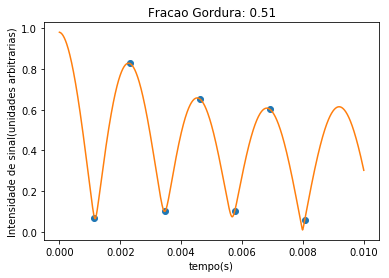

parametro dado:
0.53
paramatro encontrado:
0.53


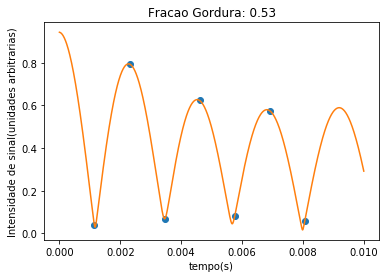

parametro dado:
0.55
paramatro encontrado:
0.55


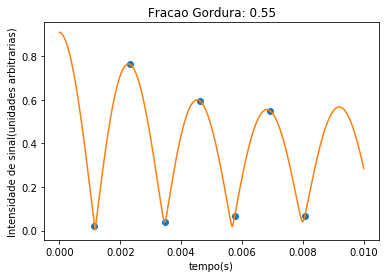

parametro dado:
0.57
paramatro encontrado:
0.57


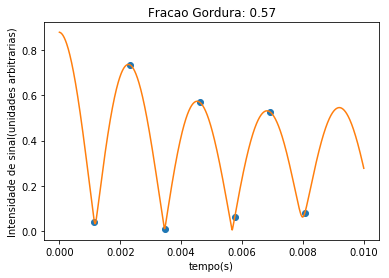

parametro dado:
0.59
paramatro encontrado:
0.59


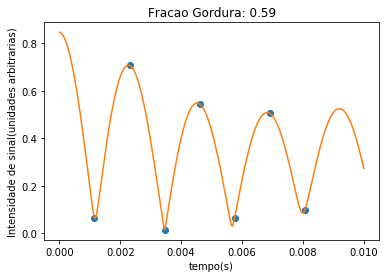

parametro dado:
0.61
paramatro encontrado:
0.510685131685


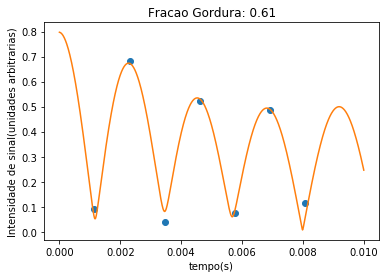

parametro dado:
0.63
paramatro encontrado:
0.478493401052


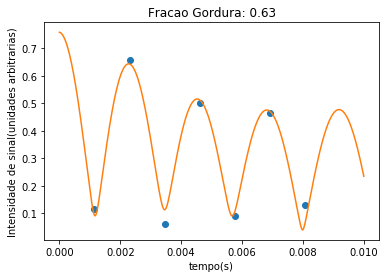

parametro dado:
0.65
paramatro encontrado:
0.453264578435


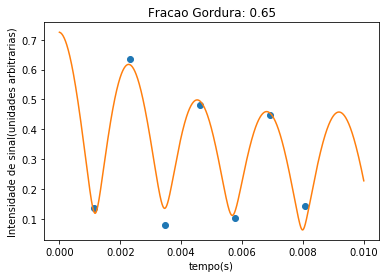

parametro dado:
0.67
paramatro encontrado:
0.429280934995


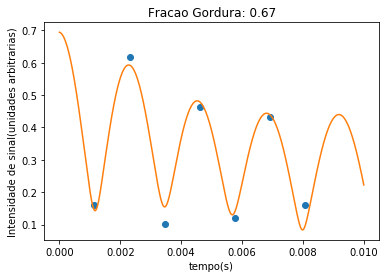

parametro dado:
0.69
paramatro encontrado:
0.405375546689


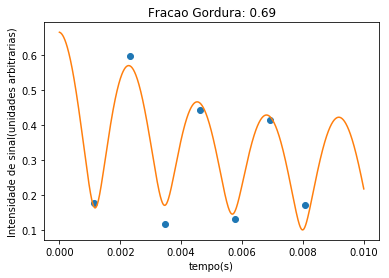

parametro dado:
0.71
paramatro encontrado:
0.381173669885


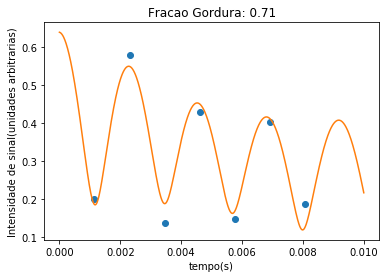

parametro dado:
0.73
paramatro encontrado:
0.356513885001


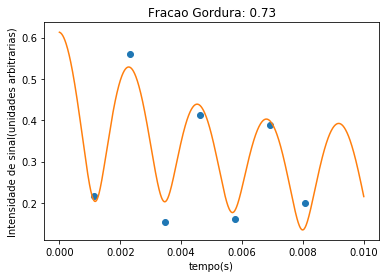

parametro dado:
0.75
paramatro encontrado:
0.331309520173


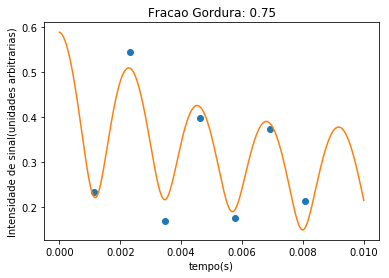

parametro dado:
0.77
paramatro encontrado:
0.305504018707


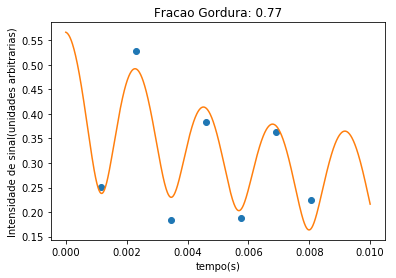

parametro dado:
0.79
paramatro encontrado:
0.27905424613


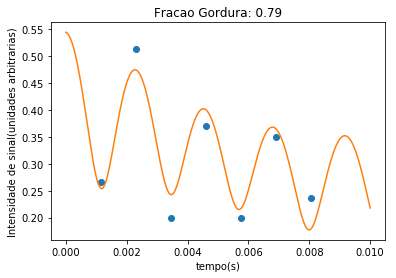

parametro dado:
0.81
paramatro encontrado:
0.251923150248


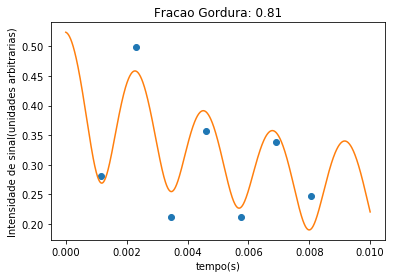

parametro dado:
0.83
paramatro encontrado:
0.224076327891


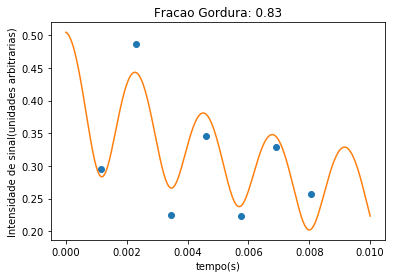

parametro dado:
0.85
paramatro encontrado:
0.195480230846


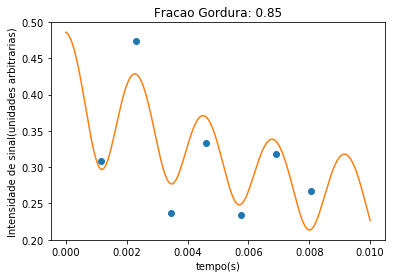

parametro dado:
0.87
paramatro encontrado:
0.166101155406


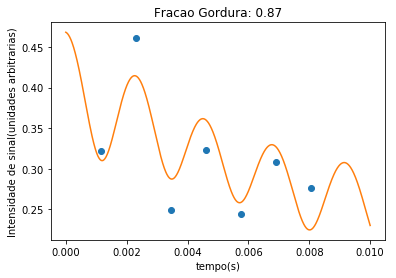

parametro dado:
0.89
paramatro encontrado:
0.13590462217


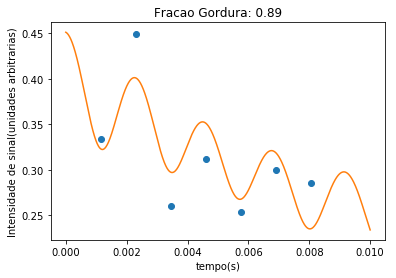

parametro dado:
0.91
paramatro encontrado:
0.104854955893


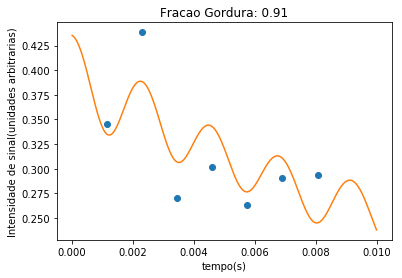

parametro dado:
0.93
paramatro encontrado:
0.0729150037383


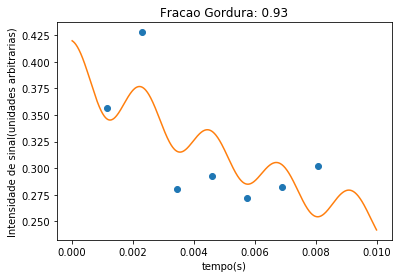

parametro dado:
0.95
paramatro encontrado:
0.0400458655423


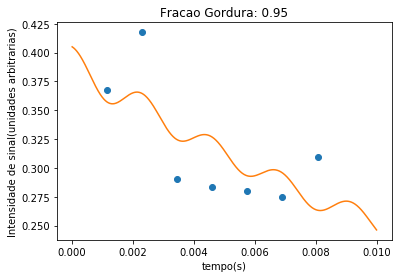

parametro dado:
0.97
paramatro encontrado:
0.00620666851805


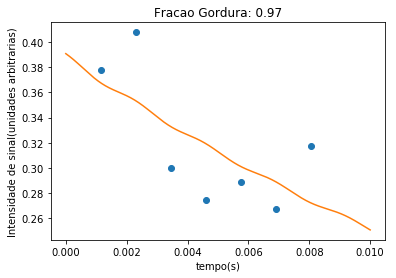

parametro dado:
0.99
paramatro encontrado:
-0.0286455882536


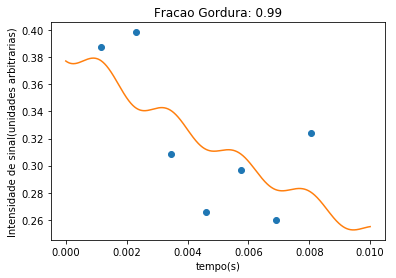

In [4]:
x = continuous_timeseries()
ff = list(np.linspace(0.01,0.99)) # fat fraction
fitted_parameter1 = []

for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata) # valor inicial  livre
    fitted_parameter1.append(fitted_par)
    
    print('parametro dado:')
    print(n)
    print('paramatro encontrado:')
    print(calc_fatfrac(fitted_par))
    
    plt.plot(xdata, ydata, 'o')
    plt.plot(x, gen_GRE(x, *fitted_par))
    
    plt.xlabel('tempo(s)')
    plt.ylabel('Intensidade de sinal(unidades arbitrarias)')
    plt.title('Fracao Gordura: {}'.format(n))
    plt.show()

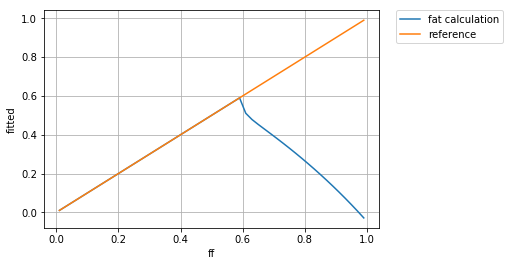

In [5]:
fitted1 = np.array([calc_fatfrac(x) for x in fitted_parameter1])
ff = np.array(ff)

plt.plot(ff, fitted1, '-', label='fat calculation', lw=1.5)
plt.plot(ff, ff, '-', label='reference', lw=1.5)

plt.xlabel('ff')
plt.ylabel('fitted')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
plt.grid(True)
plt.show()

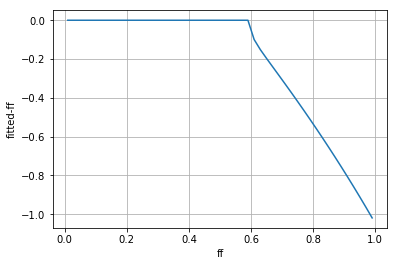

In [6]:
plt.plot(ff, (fitted1-ff), lw=1.5)
plt.xlabel('ff')
plt.ylabel('fitted-ff')
plt.grid(True)
plt.show()

# Atribuindo valores iniciais verdadeiros

parametro dado:
0.01
paramatro encontrado:
0.01


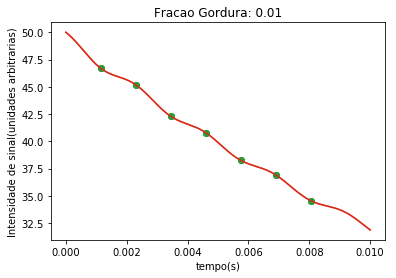

parametro dado:
0.03
paramatro encontrado:
0.03


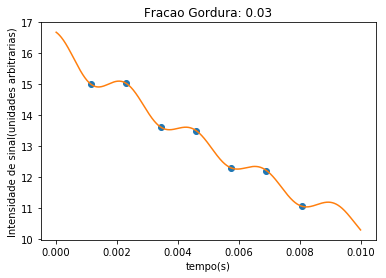

parametro dado:
0.05
paramatro encontrado:
0.05


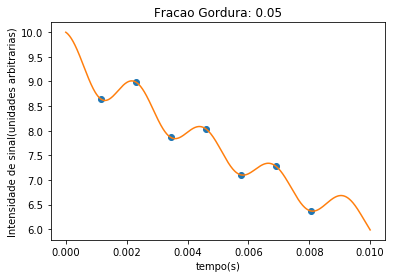

parametro dado:
0.07
paramatro encontrado:
0.07


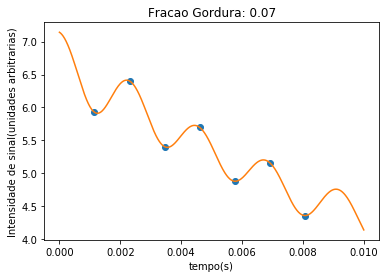

parametro dado:
0.09
paramatro encontrado:
0.09


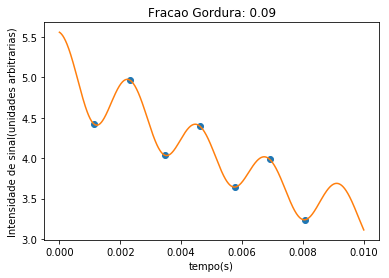

parametro dado:
0.11
paramatro encontrado:
0.11


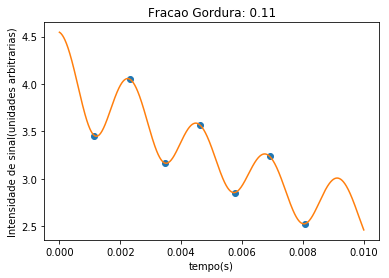

parametro dado:
0.13
paramatro encontrado:
0.13


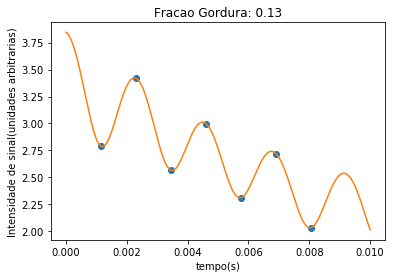

parametro dado:
0.15
paramatro encontrado:
0.15


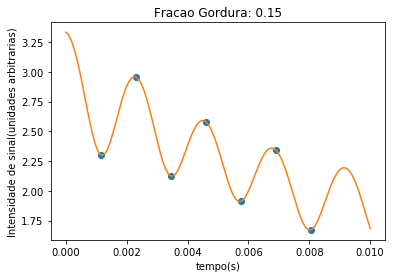

parametro dado:
0.17
paramatro encontrado:
0.17


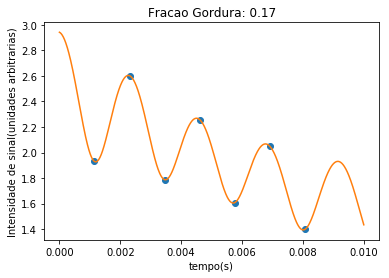

parametro dado:
0.19
paramatro encontrado:
0.19


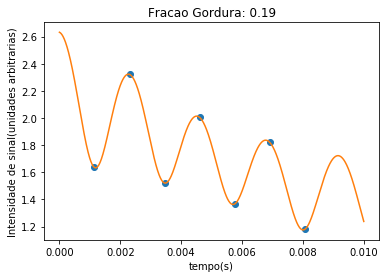

parametro dado:
0.21
paramatro encontrado:
0.21


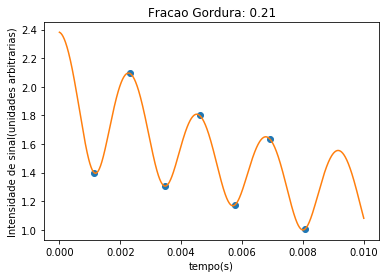

parametro dado:
0.23
paramatro encontrado:
0.23


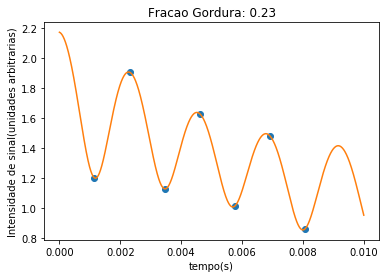

parametro dado:
0.25
paramatro encontrado:
0.25


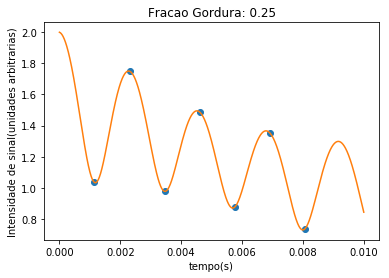

parametro dado:
0.27
paramatro encontrado:
0.27


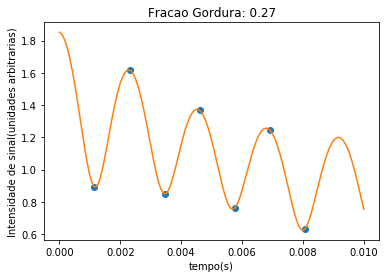

parametro dado:
0.29
paramatro encontrado:
0.29


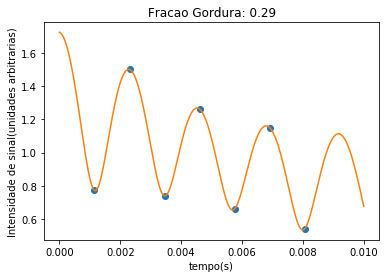

parametro dado:
0.31
paramatro encontrado:
0.31


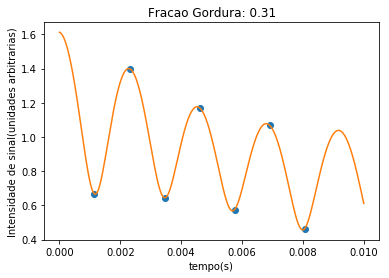

parametro dado:
0.33
paramatro encontrado:
0.33


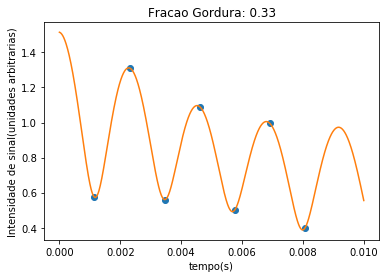

parametro dado:
0.35
paramatro encontrado:
0.35


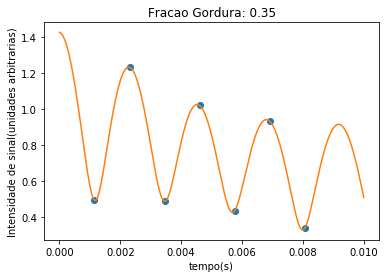

parametro dado:
0.37
paramatro encontrado:
0.37


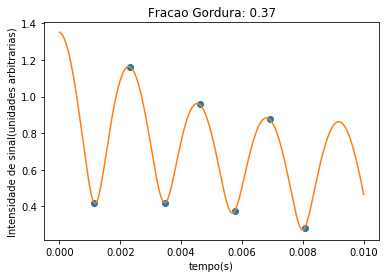

parametro dado:
0.39
paramatro encontrado:
0.39


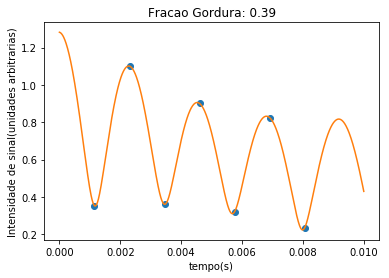

parametro dado:
0.41
paramatro encontrado:
0.41


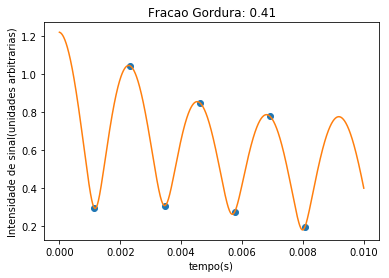

parametro dado:
0.43
paramatro encontrado:
0.43


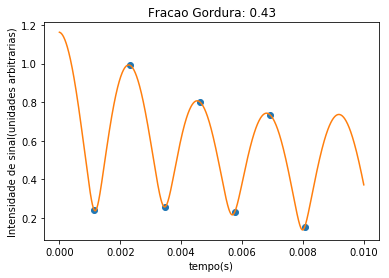

parametro dado:
0.45
paramatro encontrado:
0.45


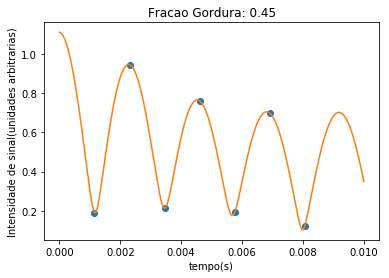

parametro dado:
0.47
paramatro encontrado:
0.47


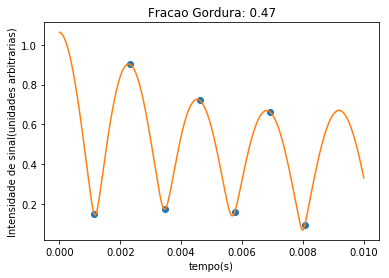

parametro dado:
0.49
paramatro encontrado:
0.49


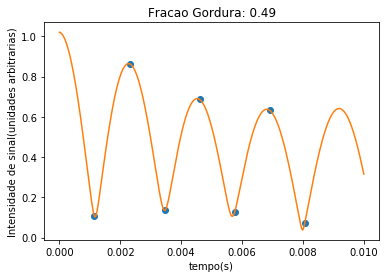

parametro dado:
0.51
paramatro encontrado:
0.51


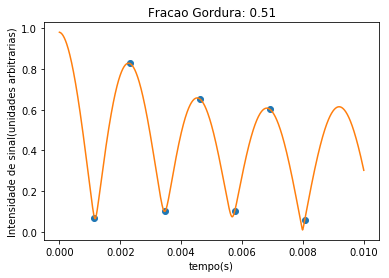

parametro dado:
0.53
paramatro encontrado:
0.53


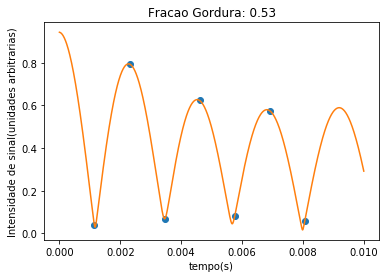

parametro dado:
0.55
paramatro encontrado:
0.55


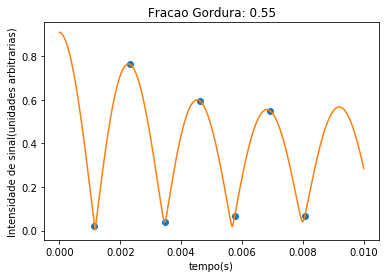

parametro dado:
0.57
paramatro encontrado:
0.57


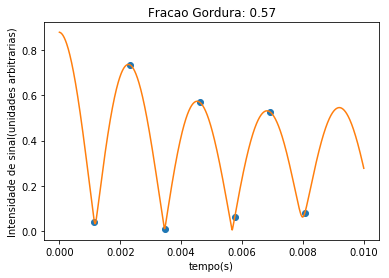

parametro dado:
0.59
paramatro encontrado:
0.59


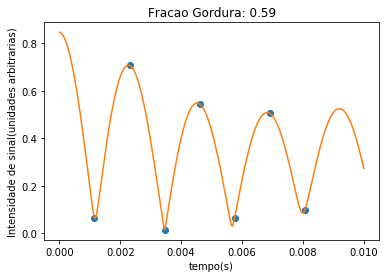

parametro dado:
0.61
paramatro encontrado:
0.61


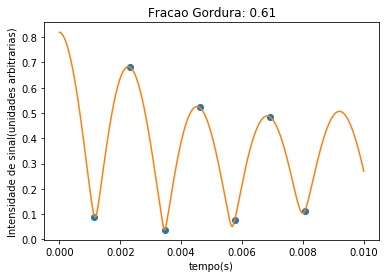

parametro dado:
0.63
paramatro encontrado:
0.63


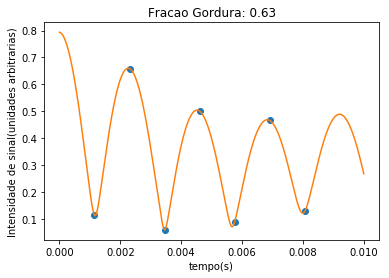

parametro dado:
0.65
paramatro encontrado:
0.65


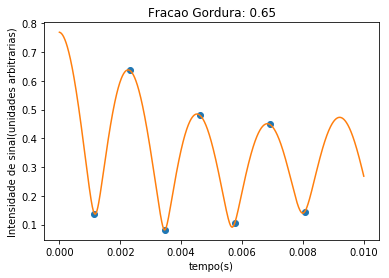

parametro dado:
0.67
paramatro encontrado:
0.67


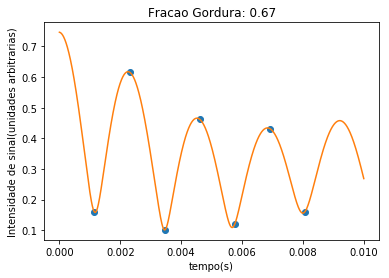

parametro dado:
0.69
paramatro encontrado:
0.69


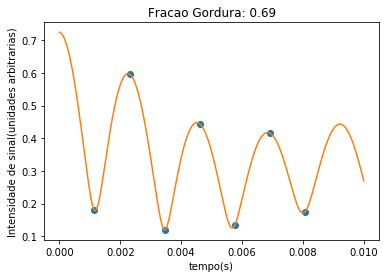

parametro dado:
0.71
paramatro encontrado:
0.71


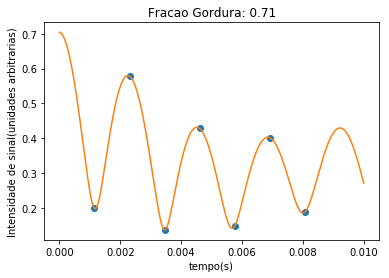

parametro dado:
0.73
paramatro encontrado:
0.73


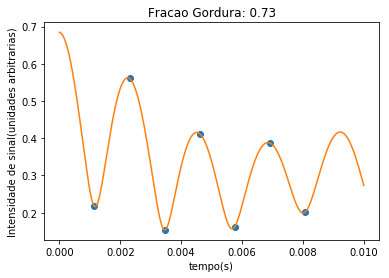

parametro dado:
0.75
paramatro encontrado:
0.75


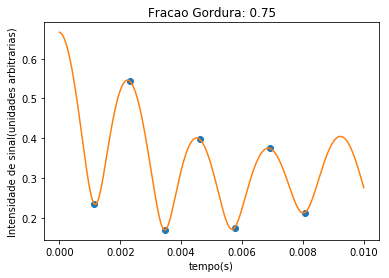

parametro dado:
0.77
paramatro encontrado:
0.77


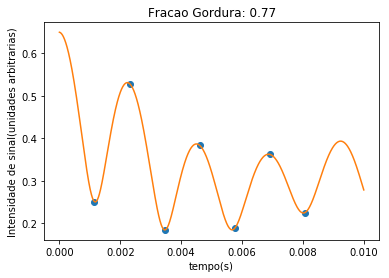

parametro dado:
0.79
paramatro encontrado:
0.79


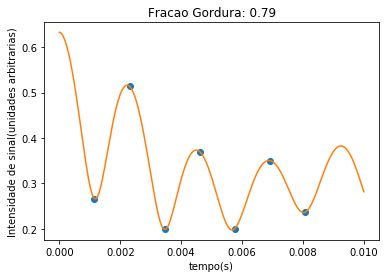

parametro dado:
0.81
paramatro encontrado:
0.81


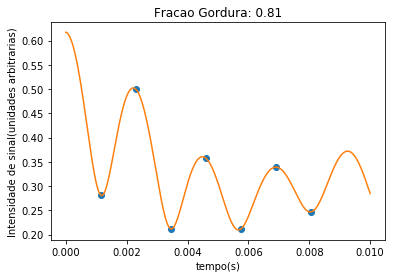

parametro dado:
0.83
paramatro encontrado:
0.83


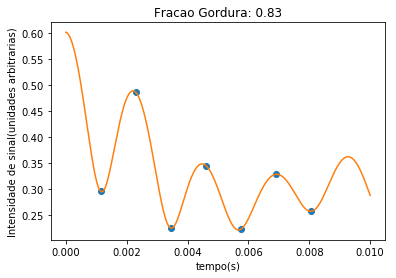

parametro dado:
0.85
paramatro encontrado:
0.85


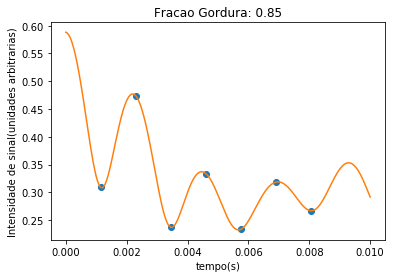

parametro dado:
0.87
paramatro encontrado:
0.87


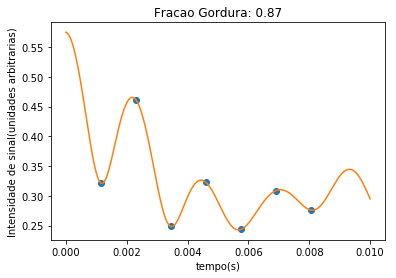

parametro dado:
0.89
paramatro encontrado:
0.89


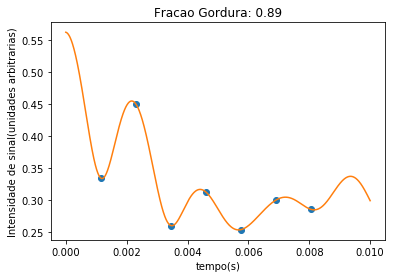

parametro dado:
0.91
paramatro encontrado:
0.91


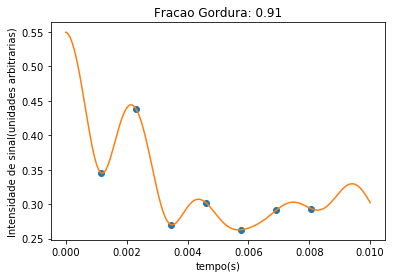

parametro dado:
0.93
paramatro encontrado:
0.93


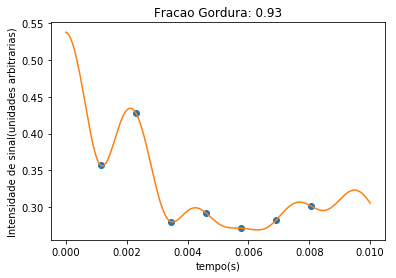

parametro dado:
0.95
paramatro encontrado:
0.95


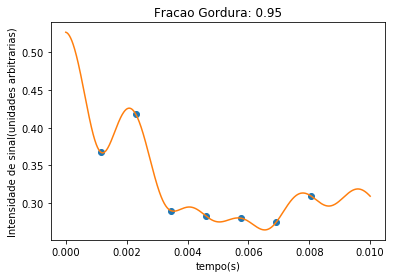

parametro dado:
0.97
paramatro encontrado:
0.97


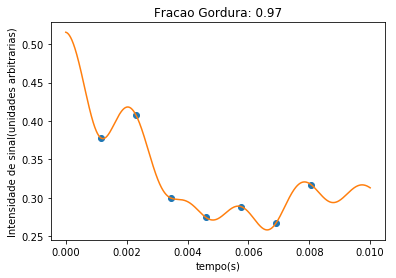

parametro dado:
0.99
paramatro encontrado:
0.99


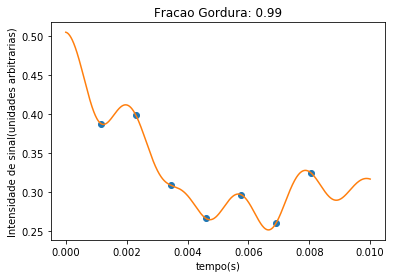

In [8]:
x = continuous_timeseries()
ff = list(np.linspace(0.01,0.99))
fitted_parameter2 = []

for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    p0 = [rho_fat, rho_water]
    fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) # valor inicial correto
    fitted_parameter2.append(fitted_par)
    
    print('parametro dado:')
    print(n)
    print('paramatro encontrado:')
    print(calc_fatfrac(fitted_par))
    
    plt.plot(xdata, ydata, 'o')
    plt.plot(x, gen_GRE(x, *fitted_par))
    
    plt.xlabel('tempo(s)')
    plt.ylabel('Intensidade de sinal(unidades arbitrarias)')
    plt.title('Fracao Gordura: {}'.format(n))
    plt.show()

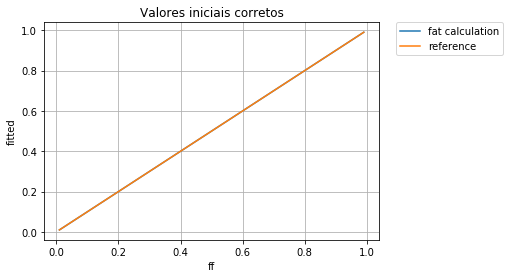

In [9]:
fitted2 = np.array([calc_fatfrac(x) for x in fitted_parameter2])
ff = np.array(ff)

plt.plot(ff, fitted2, '-', label='fat calculation', lw=1.5)
plt.plot(ff, ff, '-', label='reference', lw=1.5)

plt.title('Valores iniciais corretos')
plt.xlabel('ff')
plt.ylabel('fitted')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
plt.grid(True)
plt.show()

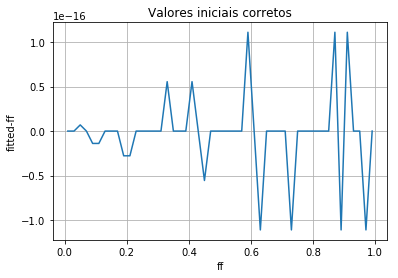

[  0.00000000e+00   0.00000000e+00   6.93889390e-18   0.00000000e+00
  -1.38777878e-17  -1.38777878e-17   0.00000000e+00   0.00000000e+00
   0.00000000e+00  -2.77555756e-17  -2.77555756e-17   0.00000000e+00
   0.00000000e+00   0.00000000e+00   0.00000000e+00   0.00000000e+00
   5.55111512e-17   0.00000000e+00   0.00000000e+00   0.00000000e+00
   5.55111512e-17   0.00000000e+00  -5.55111512e-17   0.00000000e+00
   0.00000000e+00   0.00000000e+00   0.00000000e+00   0.00000000e+00
   0.00000000e+00   1.11022302e-16   0.00000000e+00  -1.11022302e-16
   0.00000000e+00   0.00000000e+00   0.00000000e+00   0.00000000e+00
  -1.11022302e-16   0.00000000e+00   0.00000000e+00   0.00000000e+00
   0.00000000e+00   0.00000000e+00   0.00000000e+00   1.11022302e-16
  -1.11022302e-16   1.11022302e-16   0.00000000e+00   0.00000000e+00
  -1.11022302e-16   0.00000000e+00]


In [10]:
plt.plot(ff, (fitted2-ff), lw=1.5)
plt.title('Valores iniciais corretos')
plt.xlabel('ff')
plt.ylabel('fitted-ff')
plt.grid(True)
plt.show()
print(fitted2-ff)

# Variando os valores iniciais na casa de 0.01 (de forma randomica)

parametro dado:
0.01
paramatro encontrado:
0.01


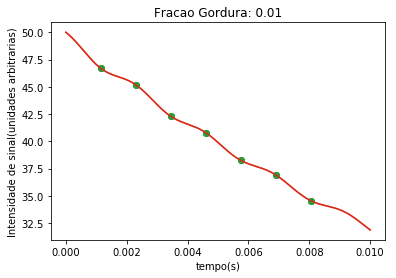

parametro dado:
0.03
paramatro encontrado:
0.03


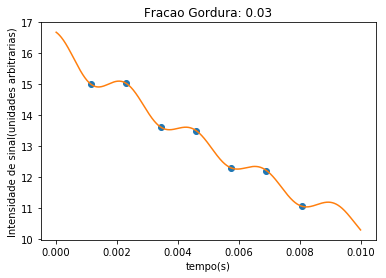

parametro dado:
0.05
paramatro encontrado:
0.05


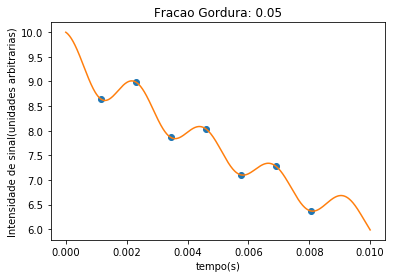

parametro dado:
0.07
paramatro encontrado:
0.07


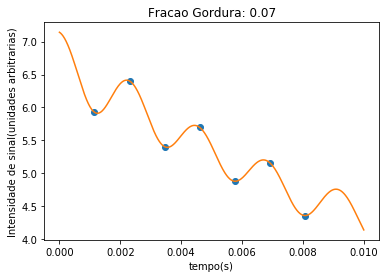

parametro dado:
0.09
paramatro encontrado:
0.09


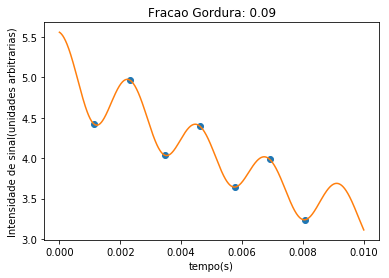

parametro dado:
0.11
paramatro encontrado:
0.11


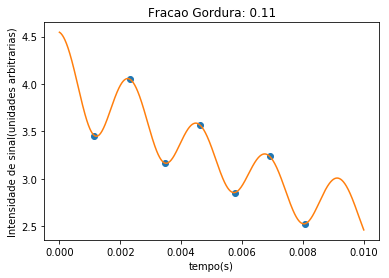

parametro dado:
0.13
paramatro encontrado:
0.13


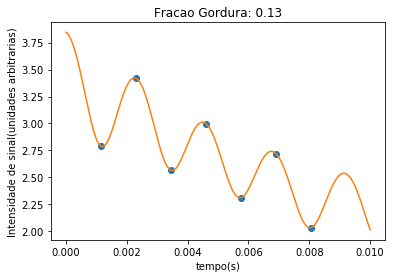

parametro dado:
0.15
paramatro encontrado:
0.15


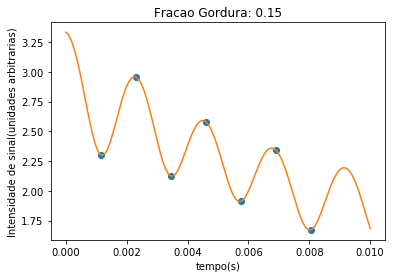

parametro dado:
0.17
paramatro encontrado:
0.17


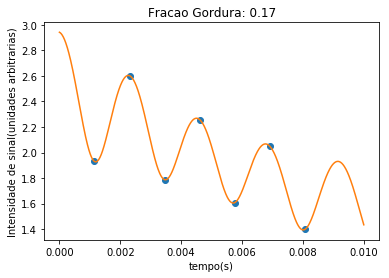

parametro dado:
0.19
paramatro encontrado:
0.19


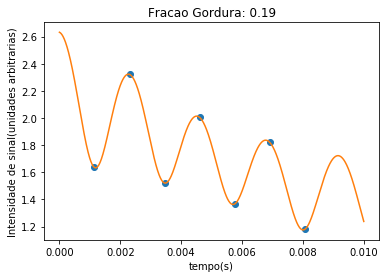

parametro dado:
0.21
paramatro encontrado:
0.21


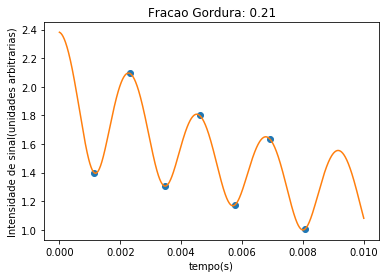

parametro dado:
0.23
paramatro encontrado:
0.23


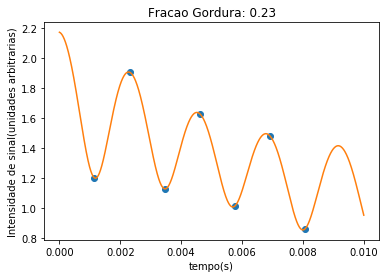

parametro dado:
0.25
paramatro encontrado:
0.25


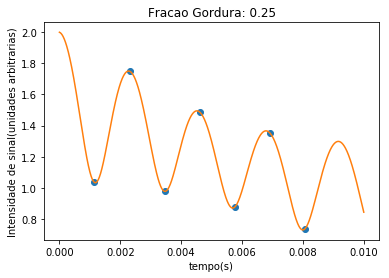

parametro dado:
0.27
paramatro encontrado:
0.27


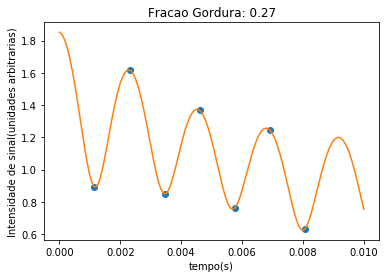

parametro dado:
0.29
paramatro encontrado:
0.29


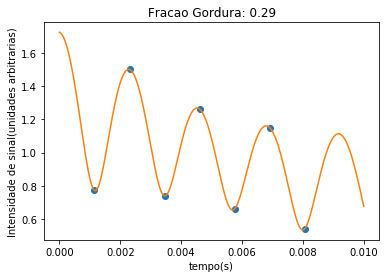

parametro dado:
0.31
paramatro encontrado:
0.31


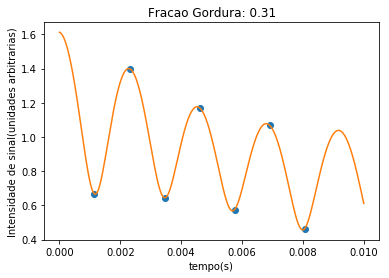

parametro dado:
0.33
paramatro encontrado:
0.33


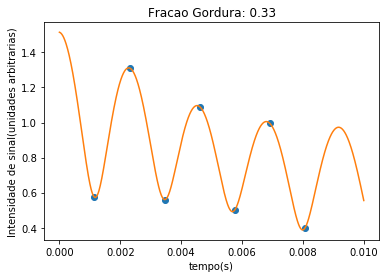

parametro dado:
0.35
paramatro encontrado:
0.35


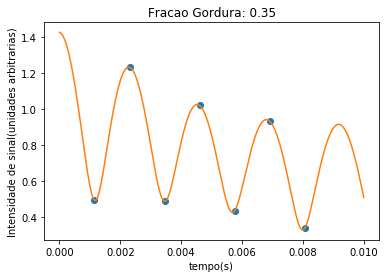

parametro dado:
0.37
paramatro encontrado:
0.37


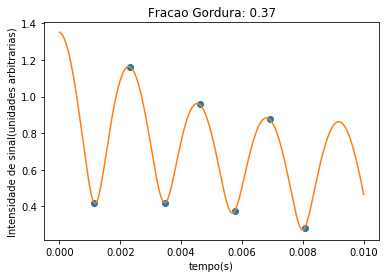

parametro dado:
0.39
paramatro encontrado:
0.39


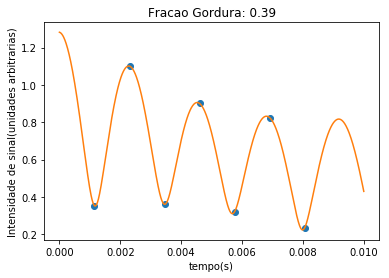

parametro dado:
0.41
paramatro encontrado:
0.41


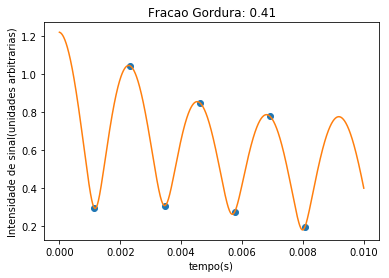

parametro dado:
0.43
paramatro encontrado:
0.43


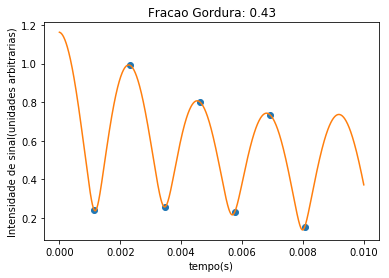

parametro dado:
0.45
paramatro encontrado:
0.45


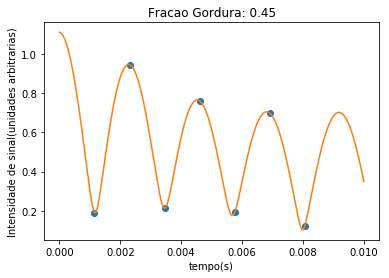

parametro dado:
0.47
paramatro encontrado:
0.47


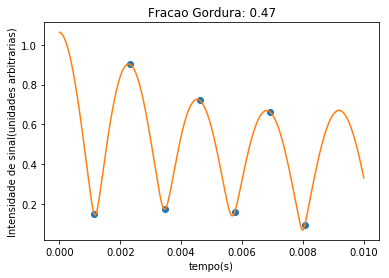

parametro dado:
0.49
paramatro encontrado:
0.49


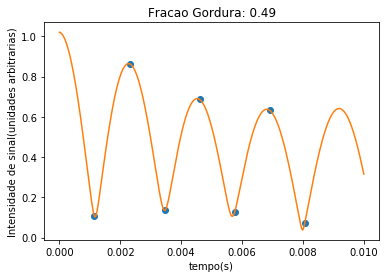

parametro dado:
0.51
paramatro encontrado:
0.51


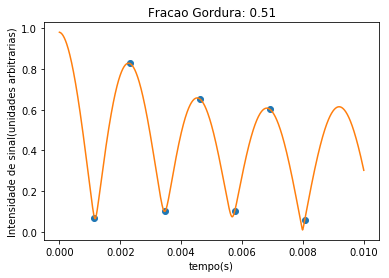

parametro dado:
0.53
paramatro encontrado:
0.53


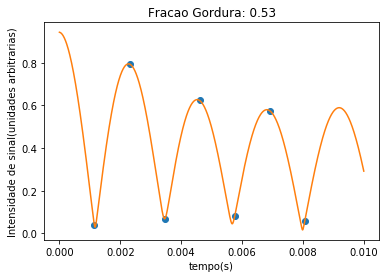

parametro dado:
0.55
paramatro encontrado:
0.55


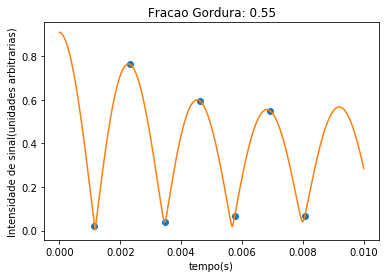

parametro dado:
0.57
paramatro encontrado:
0.57


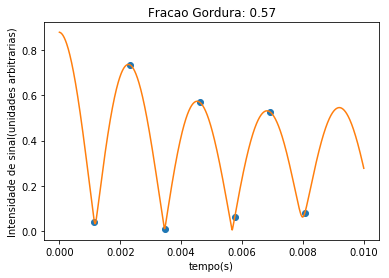

parametro dado:
0.59
paramatro encontrado:
0.59


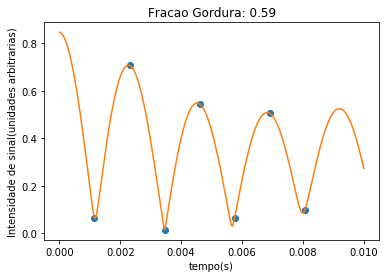

parametro dado:
0.61
paramatro encontrado:
0.61


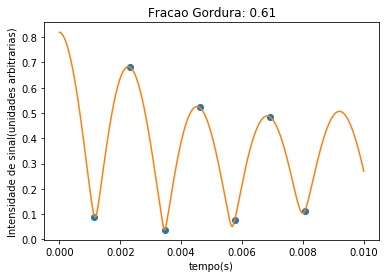

parametro dado:
0.63
paramatro encontrado:
0.63


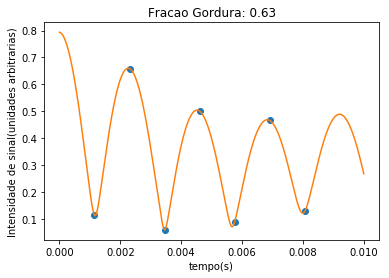

parametro dado:
0.65
paramatro encontrado:
0.65


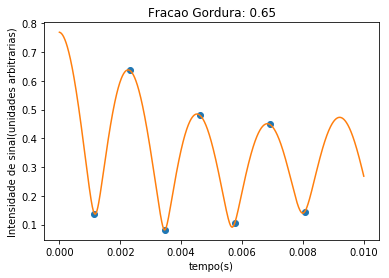

parametro dado:
0.67
paramatro encontrado:
0.67


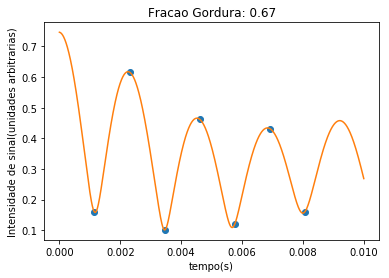

parametro dado:
0.69
paramatro encontrado:
0.69


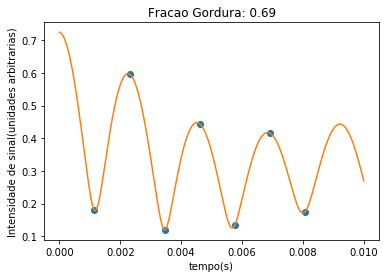

parametro dado:
0.71
paramatro encontrado:
0.71


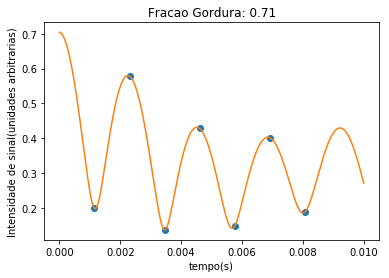

parametro dado:
0.73
paramatro encontrado:
0.73


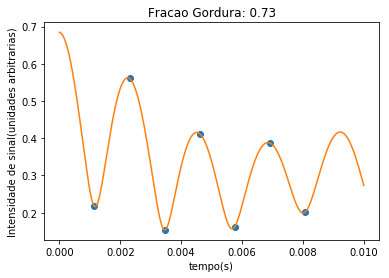

parametro dado:
0.75
paramatro encontrado:
0.75


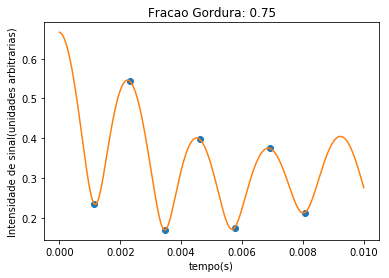

parametro dado:
0.77
paramatro encontrado:
0.77


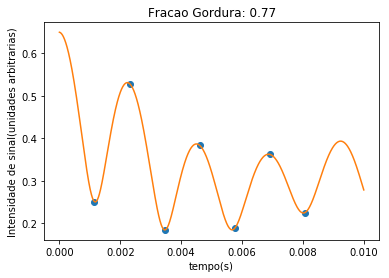

parametro dado:
0.79
paramatro encontrado:
0.79


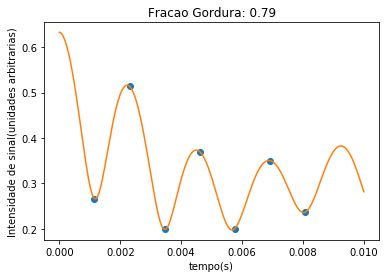

parametro dado:
0.81
paramatro encontrado:
0.81


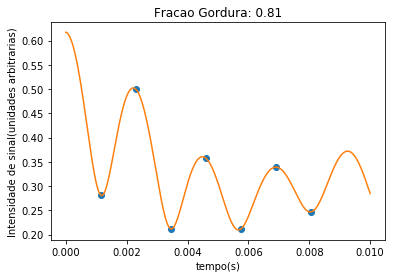

parametro dado:
0.83
paramatro encontrado:
0.83


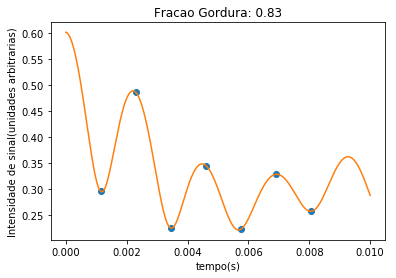

parametro dado:
0.85
paramatro encontrado:
0.85


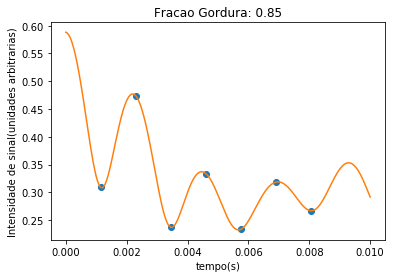

parametro dado:
0.87
paramatro encontrado:
0.87


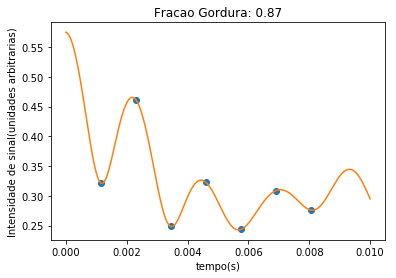

parametro dado:
0.89
paramatro encontrado:
0.89


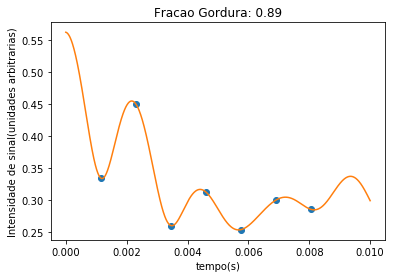

parametro dado:
0.91
paramatro encontrado:
0.91


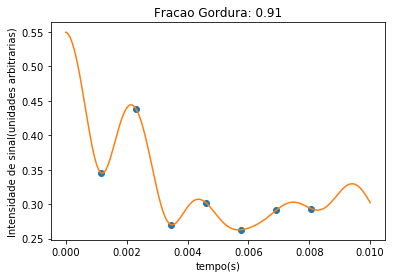

parametro dado:
0.93
paramatro encontrado:
0.93


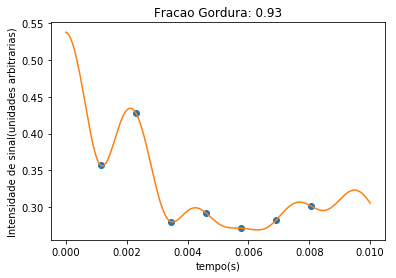

parametro dado:
0.95
paramatro encontrado:
0.95


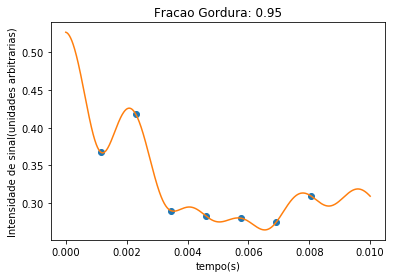

parametro dado:
0.97
paramatro encontrado:
0.97


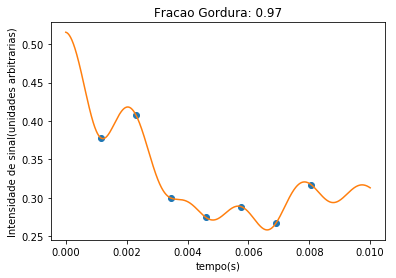

parametro dado:
0.99
paramatro encontrado:
0.99


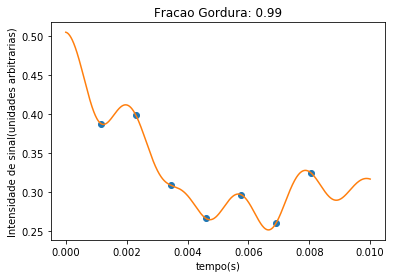

In [13]:
x = continuous_timeseries()
ff = list(np.linspace(0.01,0.99))
fitted_parameter3 = []

for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    p0 = [rho_fat + np.random.rand()*10**(-1), rho_water + np.random.rand()*10**(-1)]
    fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) # valores iniciais + random em 0.01
    fitted_parameter3.append(fitted_par)
    
    print('parametro dado:')
    print(n)
    print('paramatro encontrado:')
    print(calc_fatfrac(fitted_par))
    
    plt.plot(xdata, ydata, 'o')
    plt.plot(x, gen_GRE(x, *fitted_par))
    
    plt.xlabel('tempo(s)')
    plt.ylabel('Intensidade de sinal(unidades arbitrarias)')
    plt.title('Fracao Gordura: {}'.format(n))
    plt.show()

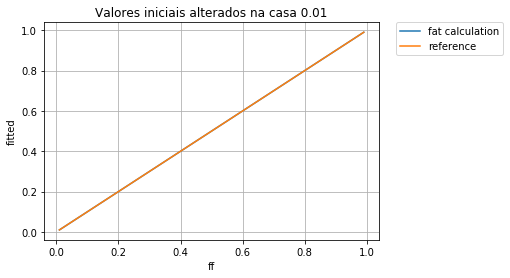

In [14]:
fitted3 = np.array([calc_fatfrac(x) for x in fitted_parameter3])
ff = np.array(ff)

plt.plot(ff, fitted3, '-', label='fat calculation', lw=1.5)
plt.plot(ff, ff, '-', label='reference', lw=1.5)

plt.title('Valores iniciais alterados na casa 0.01')
plt.xlabel('ff')
plt.ylabel('fitted')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
plt.grid(True)
plt.show()

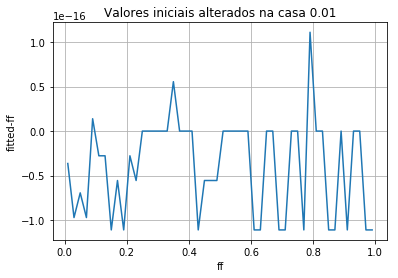

In [15]:
plt.plot(ff, (fitted3-ff), lw=1.5)
plt.title('Valores iniciais alterados na casa 0.01')
plt.xlabel('ff')
plt.ylabel('fitted-ff')
plt.grid(True)
plt.show()

# Variando os valores iniciais na casa de 0.1 (de forma randomica)

parametro dado
0.01
paramatro encontrado
0.01
valores iniciais + np.random.rand()
[0.51703588208894635, 50.385156262341681]
rhos
(array(0.5), array(49.5))


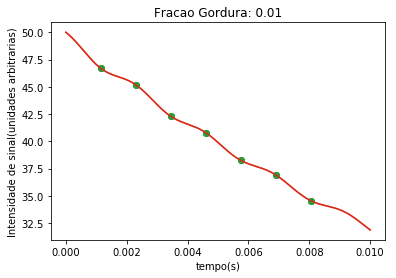

parametro dado
0.03
paramatro encontrado
0.03
valores iniciais + np.random.rand()
[1.1121202513685344, 16.398841957128575]
rhos
(array(0.5), array(16.166666666666668))


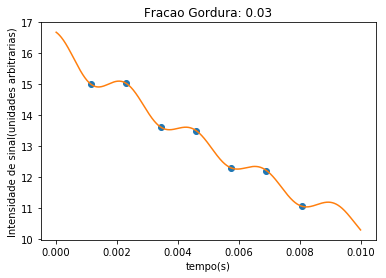

parametro dado
0.05
paramatro encontrado
0.05
valores iniciais + np.random.rand()
[0.58068311197418521, 10.140814386601432]
rhos
(array(0.5), array(9.499999999999998))


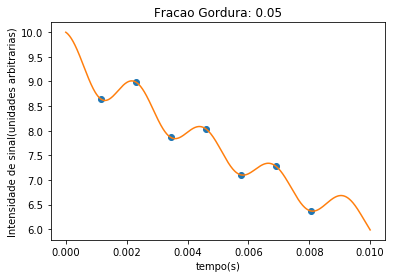

parametro dado
0.07
paramatro encontrado
0.07
valores iniciais + np.random.rand()
[0.78481013827940627, 6.6667544251923134]
rhos
(array(0.5), array(6.642857142857144))


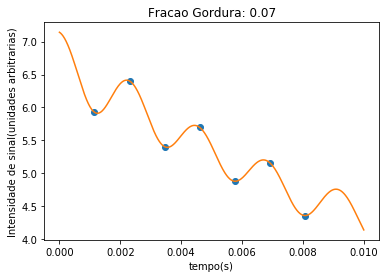

parametro dado
0.09
paramatro encontrado
0.09
valores iniciais + np.random.rand()
[1.2766187740876476, 6.0418818087333097]
rhos
(array(0.5), array(5.055555555555556))


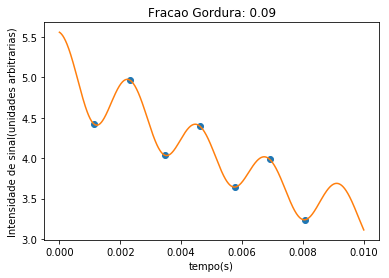

parametro dado
0.11
paramatro encontrado
0.11
valores iniciais + np.random.rand()
[1.2706449829801238, 4.6506755207028636]
rhos
(array(0.5), array(4.045454545454546))


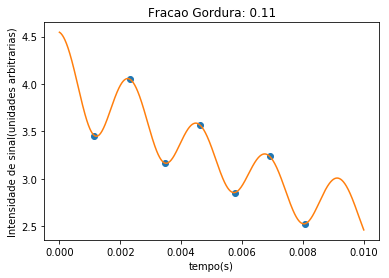

parametro dado
0.13
paramatro encontrado
0.13
valores iniciais + np.random.rand()
[0.62986315006463756, 4.3446343080552854]
rhos
(array(0.5), array(3.346153846153846))


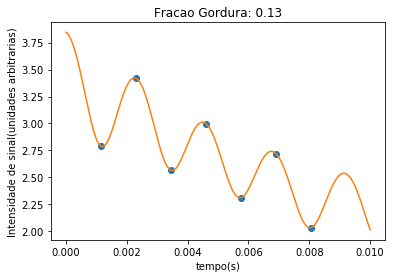

parametro dado
0.15
paramatro encontrado
0.15
valores iniciais + np.random.rand()
[1.1215685782729301, 3.2446428526188904]
rhos
(array(0.5), array(2.833333333333333))


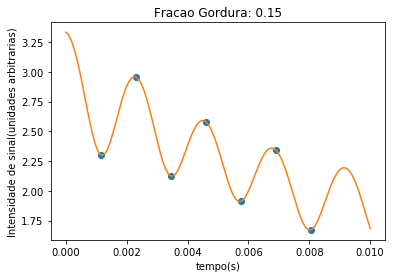

parametro dado
0.17
paramatro encontrado
0.17
valores iniciais + np.random.rand()
[0.77770537703864051, 3.2083961200850371]
rhos
(array(0.5), array(2.441176470588235))


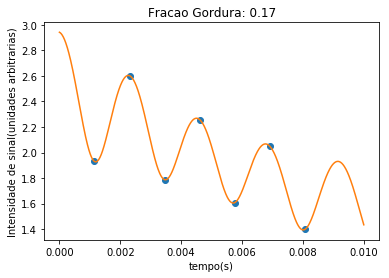

parametro dado
0.19
paramatro encontrado
0.19
valores iniciais + np.random.rand()
[1.4509757747160172, 2.2375715869174821]
rhos
(array(0.5), array(2.1315789473684212))


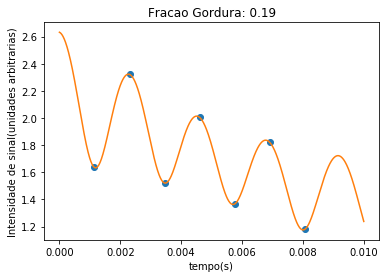

parametro dado
0.21
paramatro encontrado
0.21
valores iniciais + np.random.rand()
[0.77456391985116402, 2.5552093599428676]
rhos
(array(0.5), array(1.880952380952381))


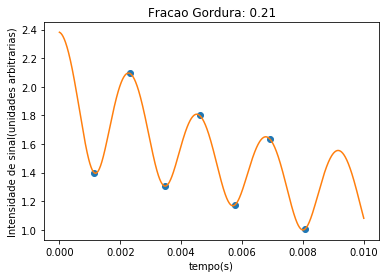

parametro dado
0.23
paramatro encontrado
0.23
valores iniciais + np.random.rand()
[1.3635545141053957, 2.2127646365203915]
rhos
(array(0.5), array(1.6739130434782608))


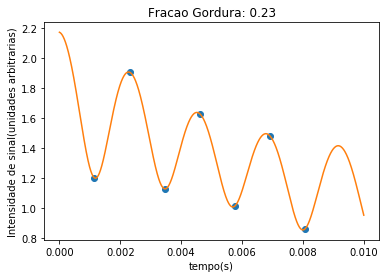

parametro dado
0.25
paramatro encontrado
0.25
valores iniciais + np.random.rand()
[0.75751102984689023, 1.6614693566349885]
rhos
(array(0.5), array(1.5))


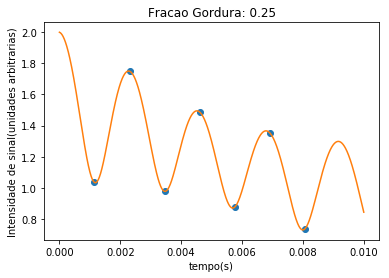

parametro dado
0.27
paramatro encontrado
0.27
valores iniciais + np.random.rand()
[1.0477256242565527, 1.6621246957533968]
rhos
(array(0.5), array(1.3518518518518516))


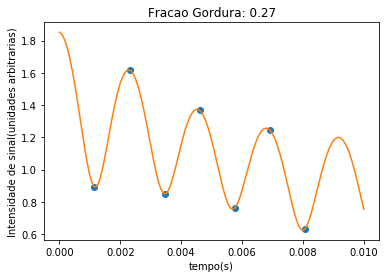

parametro dado
0.29
paramatro encontrado
0.29
valores iniciais + np.random.rand()
[1.3307218286323872, 1.6416248678049254]
rhos
(array(0.5), array(1.2241379310344827))


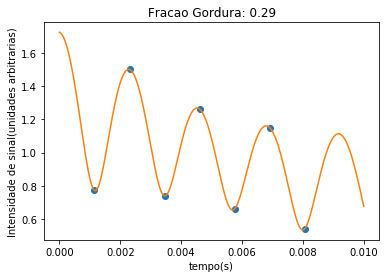

parametro dado
0.31
paramatro encontrado
0.31
valores iniciais + np.random.rand()
[0.59930278646371027, 1.5351932466041973]
rhos
(array(0.5), array(1.1129032258064515))


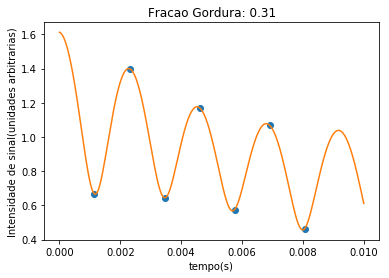

parametro dado
0.33
paramatro encontrado
0.33
valores iniciais + np.random.rand()
[0.89637935243444833, 1.866846665203201]
rhos
(array(0.5), array(1.015151515151515))


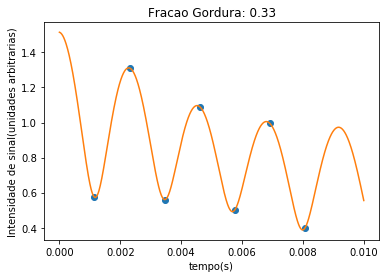

parametro dado
0.35
paramatro encontrado
0.35
valores iniciais + np.random.rand()
[1.0484667674570911, 1.497262335920662]
rhos
(array(0.5), array(0.9285714285714284))


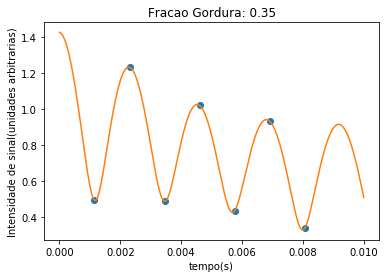

parametro dado
0.37
paramatro encontrado
0.37
valores iniciais + np.random.rand()
[0.66556507301600709, 1.2279987029030415]
rhos
(array(0.5), array(0.8513513513513513))


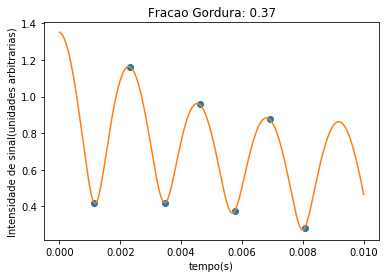

parametro dado
0.39
paramatro encontrado
0.39
valores iniciais + np.random.rand()
[1.4308150744668373, 1.7206679118300277]
rhos
(array(0.5), array(0.782051282051282))


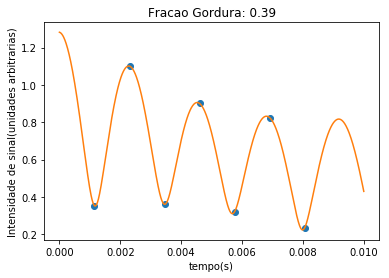

parametro dado
0.41
paramatro encontrado
0.41
valores iniciais + np.random.rand()
[0.90677776224804274, 0.7636125727261095]
rhos
(array(0.5), array(0.7195121951219511))


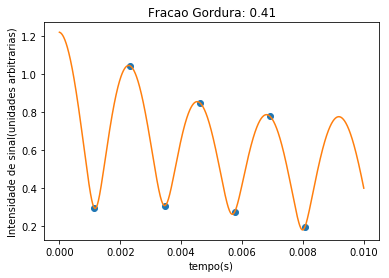

parametro dado
0.43
paramatro encontrado
0.43
valores iniciais + np.random.rand()
[1.0353681640892378, 1.1134772468156173]
rhos
(array(0.5), array(0.6627906976744187))


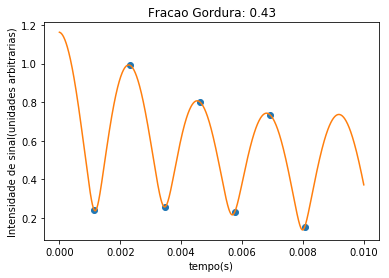

parametro dado
0.45
paramatro encontrado
0.45
valores iniciais + np.random.rand()
[0.75840796862901072, 1.3060334257099697]
rhos
(array(0.5), array(0.6111111111111112))


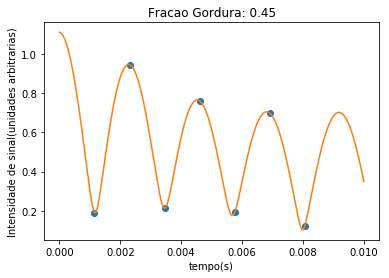

parametro dado
0.47
paramatro encontrado
0.47
valores iniciais + np.random.rand()
[1.4859756150849259, 1.5013693542650564]
rhos
(array(0.5), array(0.5638297872340425))


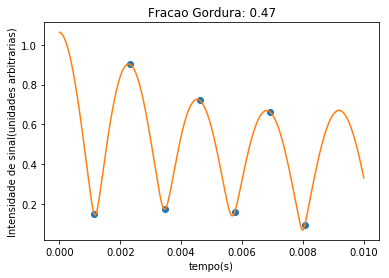

parametro dado
0.49
paramatro encontrado
0.615201478574
valores iniciais + np.random.rand()
[1.366318081997961, 0.72762063397870491]
rhos
(array(0.5), array(0.5204081632653061))


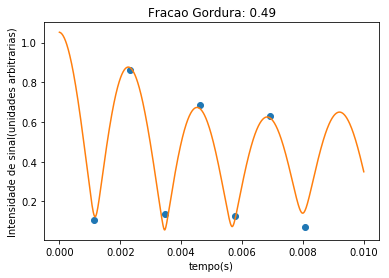

parametro dado
0.51
paramatro encontrado
0.51
valores iniciais + np.random.rand()
[1.162595142398779, 1.1461359453715616]
rhos
(array(0.5), array(0.48039215686274506))


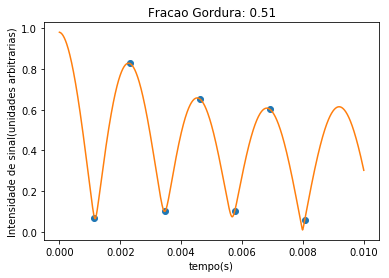

parametro dado
0.53
paramatro encontrado
0.583204553907
valores iniciais + np.random.rand()
[1.095282184982481, 0.71880017941666963]
rhos
(array(0.5), array(0.4433962264150943))


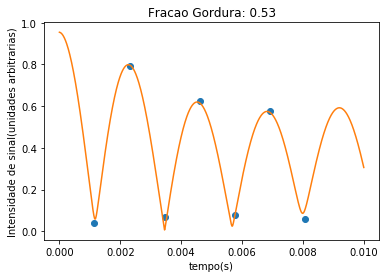

parametro dado
0.55
paramatro encontrado
0.55
valores iniciais + np.random.rand()
[0.98302566865965779, 1.2843006455929513]
rhos
(array(0.5), array(0.409090909090909))


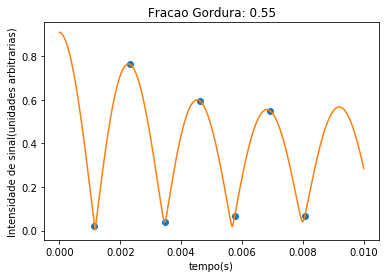

parametro dado
0.57
paramatro encontrado
0.57
valores iniciais + np.random.rand()
[1.2206890082412512, 0.49258212037485088]
rhos
(array(0.5), array(0.37719298245614025))


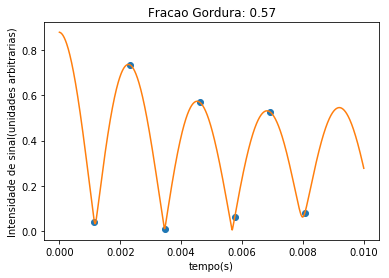

parametro dado
0.59
paramatro encontrado
0.59
valores iniciais + np.random.rand()
[0.52660679819578793, 0.66873164413505171]
rhos
(array(0.5), array(0.3474576271186441))


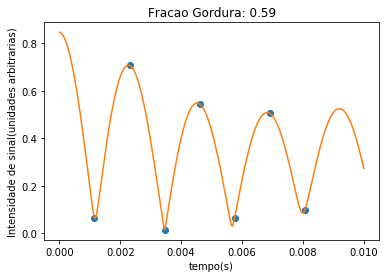

parametro dado
0.61
paramatro encontrado
0.61
valores iniciais + np.random.rand()
[0.92931708890626341, 0.61624965839849954]
rhos
(array(0.5), array(0.319672131147541))


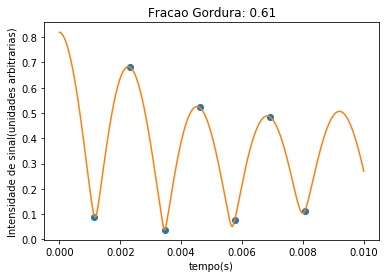

parametro dado
0.63
paramatro encontrado
0.478492164328
valores iniciais + np.random.rand()
[0.8772187690532981, 1.252272006816592]
rhos
(array(0.5), array(0.29365079365079366))


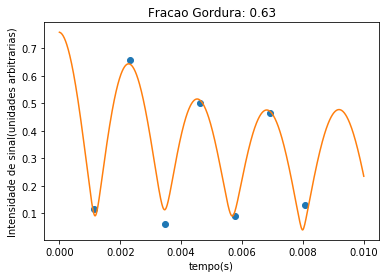

parametro dado
0.65
paramatro encontrado
0.453264536258
valores iniciais + np.random.rand()
[1.0034057794256117, 1.0341849281592963]
rhos
(array(0.5), array(0.2692307692307692))


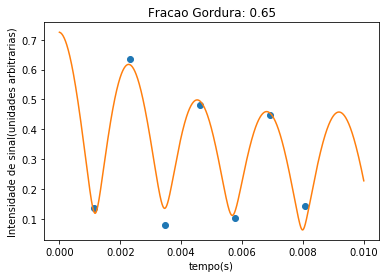

parametro dado
0.67
paramatro encontrado
0.429280719196
valores iniciais + np.random.rand()
[0.79010561187635697, 1.1695746814392562]
rhos
(array(0.5), array(0.24626865671641787))


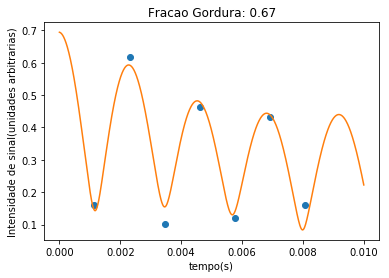

parametro dado
0.69
paramatro encontrado
0.69
valores iniciais + np.random.rand()
[0.62608375334867117, 0.30000780361944474]
rhos
(array(0.5), array(0.22463768115942023))


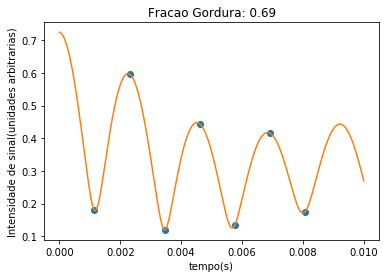

parametro dado
0.71
paramatro encontrado
0.71
valores iniciais + np.random.rand()
[1.014770077908322, 0.7509255790949394]
rhos
(array(0.5), array(0.20422535211267598))


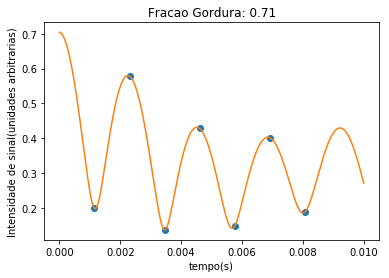

parametro dado
0.73
paramatro encontrado
0.356513908231
valores iniciais + np.random.rand()
[0.55229465459667892, 0.49473591188505289]
rhos
(array(0.5), array(0.18493150684931509))


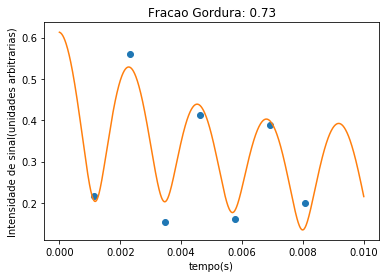

parametro dado
0.75
paramatro encontrado
0.75
valores iniciais + np.random.rand()
[1.4534935823613044, 0.69380870953389473]
rhos
(array(0.5), array(0.16666666666666666))


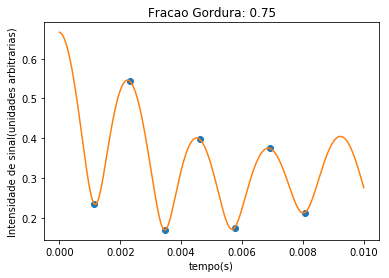

parametro dado
0.77
paramatro encontrado
0.305503994717
valores iniciais + np.random.rand()
[0.8636237729864521, 0.71568055998114799]
rhos
(array(0.5), array(0.14935064935064934))


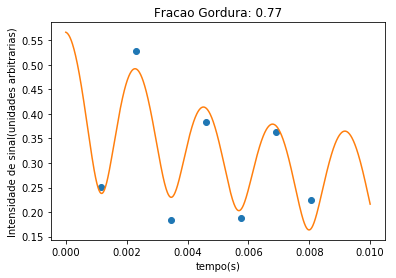

parametro dado
0.79
paramatro encontrado
0.79
valores iniciais + np.random.rand()
[1.4197755123659106, 0.25859192481367188]
rhos
(array(0.5), array(0.13291139240506325))


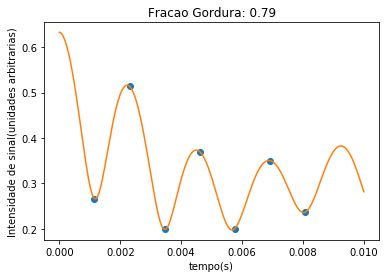

parametro dado
0.81
paramatro encontrado
0.81
valores iniciais + np.random.rand()
[1.1849463637720898, 0.82001565676461086]
rhos
(array(0.5), array(0.11728395061728392))


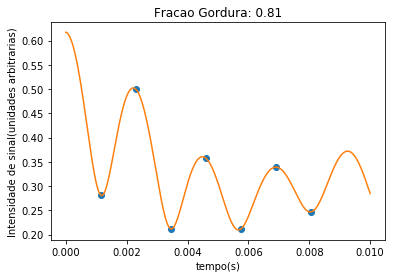

parametro dado
0.83
paramatro encontrado
0.83
valores iniciais + np.random.rand()
[1.3637957848526741, 0.19008868630448206]
rhos
(array(0.5), array(0.10240963855421682))


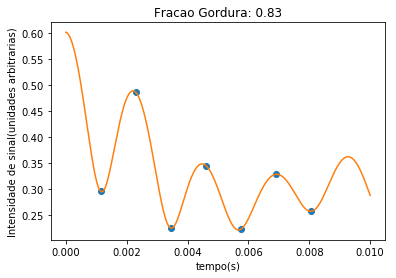

parametro dado
0.85
paramatro encontrado
0.85
valores iniciais + np.random.rand()
[0.91964623863742323, 0.53410228099447477]
rhos
(array(0.5), array(0.08823529411764708))


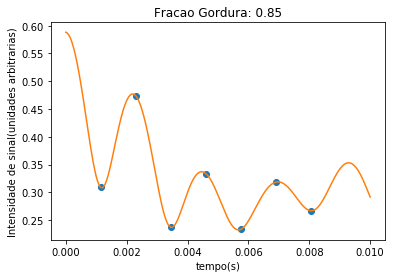

parametro dado
0.87
paramatro encontrado
0.87
valores iniciais + np.random.rand()
[1.4788622598387748, 0.95483727644008665]
rhos
(array(0.5), array(0.07471264367816093))


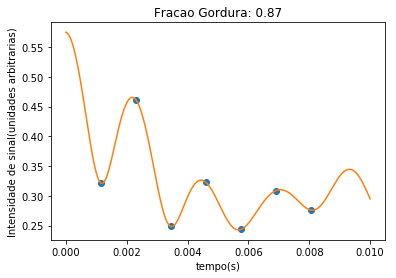

parametro dado
0.89
paramatro encontrado
0.89
valores iniciais + np.random.rand()
[1.4566996664193643, 0.76896739283768367]
rhos
(array(0.5), array(0.061797752808988755))


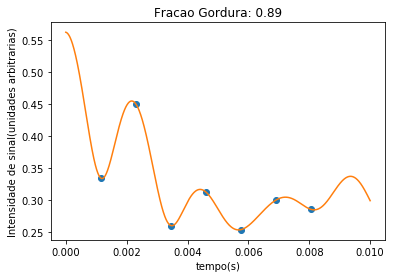

parametro dado
0.91
paramatro encontrado
0.91
valores iniciais + np.random.rand()
[0.82509018338687601, 0.5998507688786201]
rhos
(array(0.5), array(0.049450549450549434))


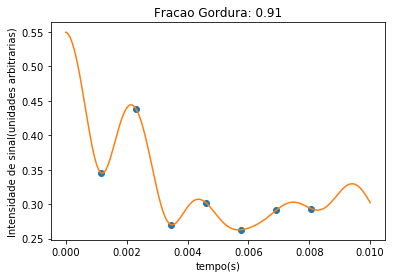

parametro dado
0.93
paramatro encontrado
0.93
valores iniciais + np.random.rand()
[0.9079405169306719, 0.34281332890964622]
rhos
(array(0.5), array(0.03763440860215051))


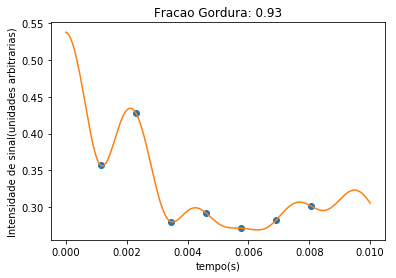

parametro dado
0.95
paramatro encontrado
0.95
valores iniciais + np.random.rand()
[1.1404941533197492, 0.12718738372826022]
rhos
(array(0.5), array(0.026315789473684174))


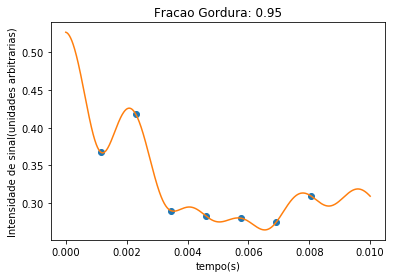

parametro dado
0.97
paramatro encontrado
0.97
valores iniciais + np.random.rand()
[0.56939980811115165, 0.29437473896901906]
rhos
(array(0.5), array(0.01546391752577321))


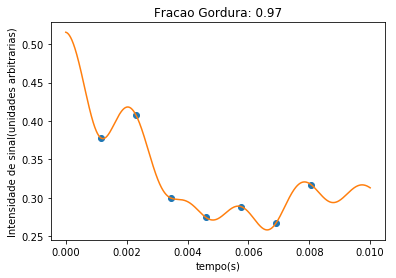

parametro dado
0.99
paramatro encontrado
0.99
valores iniciais + np.random.rand()
[0.72462972141137105, 0.51846451678574168]
rhos
(array(0.5), array(0.005050505050505055))


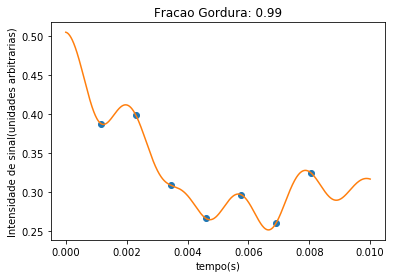

In [18]:
x = continuous_timeseries()
ff = list(np.linspace(0.01,0.99))
fitted_parameter4 = []

for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    p0 = [rho_fat + np.random.rand(), rho_water + np.random.rand()]
    fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) # valores iniciais + random em 0.1
    fitted_parameter4.append(fitted_par)
    
    print('parametro dado')
    print(n)
    print('paramatro encontrado')
    print(calc_fatfrac(fitted_par))
    print('valores iniciais + np.random.rand()')
    print(p0)
    print('rhos')
    print(rho_fat, rho_water)
    
    plt.plot(xdata, ydata, 'o')
    plt.plot(x, gen_GRE(x, *fitted_par))
    
    plt.xlabel('tempo(s)')
    plt.ylabel('Intensidade de sinal(unidades arbitrarias)')
    plt.title('Fracao Gordura: {}'.format(n))
    plt.show()

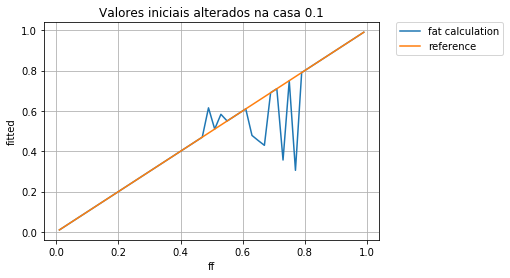

In [21]:
fitted4 = np.array([calc_fatfrac(x) for x in fitted_parameter4])
ff = np.array(ff)

plt.plot(ff, fitted4, '-', label='fat calculation', lw=1.5)
plt.plot(ff, ff, '-', label='reference', lw=1.5)

plt.title('Valores iniciais alterados na casa 0.1')
plt.xlabel('ff')
plt.ylabel('fitted')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
plt.grid(True)
plt.show()

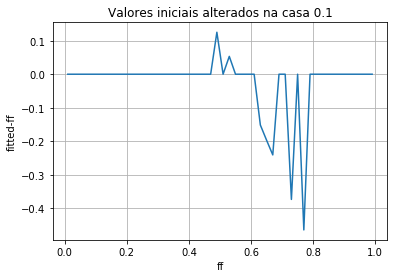

In [20]:
plt.plot(ff, (fitted4-ff), lw=1.5)
plt.title('Valores iniciais alterados na casa 0.1')
plt.xlabel('ff')
plt.ylabel('fitted-ff')
plt.grid(True)
plt.show()

## Variando os valores iniciais na casa de 1.0 (de forma randomica)

parametro dado
0.01
paramatro encontrado
0.01
valores iniciais + np.random.rand()
[8.3803268112532674, 56.072946002688738]
rhos
(array(0.5), array(49.5))


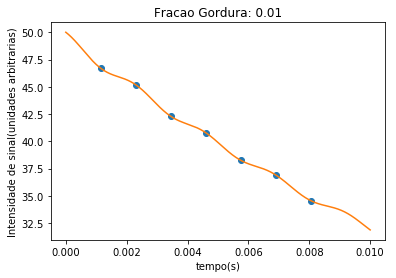

parametro dado
0.03
paramatro encontrado
0.03
valores iniciais + np.random.rand()
[2.282238972266188, 26.003721637595262]
rhos
(array(0.5), array(16.166666666666668))


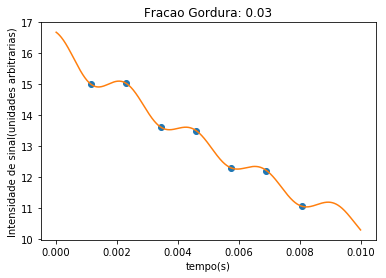

parametro dado
0.05
paramatro encontrado
0.05
valores iniciais + np.random.rand()
[9.9617031005174859, 10.973964341135325]
rhos
(array(0.5), array(9.499999999999998))


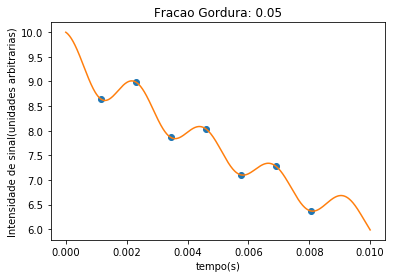

parametro dado
0.07
paramatro encontrado
0.07
valores iniciais + np.random.rand()
[8.1129251378299969, 7.5692637298117917]
rhos
(array(0.5), array(6.642857142857144))


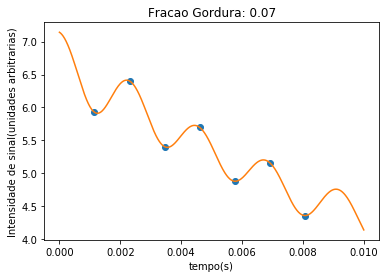

parametro dado
0.09
paramatro encontrado
0.09
valores iniciais + np.random.rand()
[5.3394248000597786, 13.380525957136669]
rhos
(array(0.5), array(5.055555555555556))


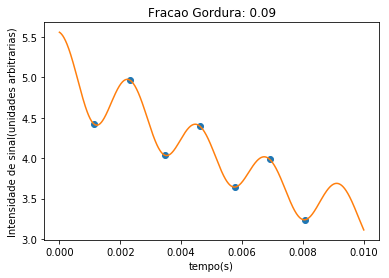

parametro dado
0.11
paramatro encontrado
0.11
valores iniciais + np.random.rand()
[10.021070523457666, 11.134243930230912]
rhos
(array(0.5), array(4.045454545454546))


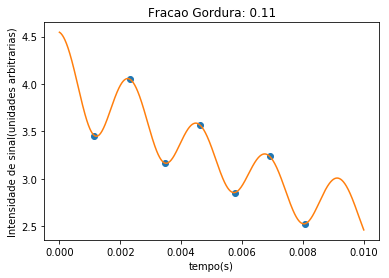

parametro dado
0.13
paramatro encontrado
0.13
valores iniciais + np.random.rand()
[1.098199550545524, 7.8977290307368451]
rhos
(array(0.5), array(3.346153846153846))


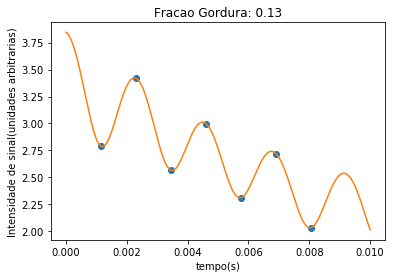

parametro dado
0.15
paramatro encontrado
0.15
valores iniciais + np.random.rand()
[4.6229608901975947, 10.363435109930226]
rhos
(array(0.5), array(2.833333333333333))


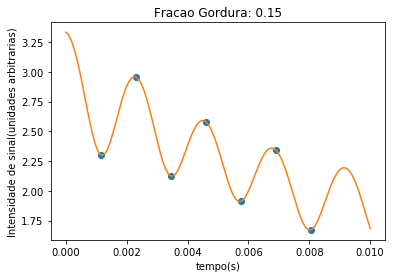

parametro dado
0.17
paramatro encontrado
0.866626366446
valores iniciais + np.random.rand()
[7.8834375166449719, 5.9506923826620319]
rhos
(array(0.5), array(2.441176470588235))


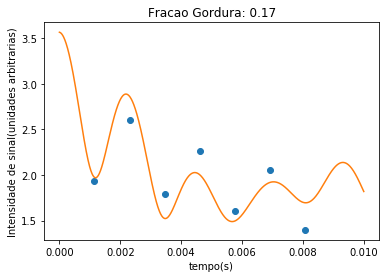

parametro dado
0.19
paramatro encontrado
0.19
valores iniciais + np.random.rand()
[2.6413132524878522, 10.762445069368386]
rhos
(array(0.5), array(2.1315789473684212))


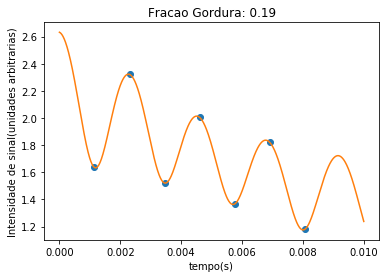

parametro dado
0.21
paramatro encontrado
0.21
valores iniciais + np.random.rand()
[3.6759576966615732, 10.008712247269569]
rhos
(array(0.5), array(1.880952380952381))


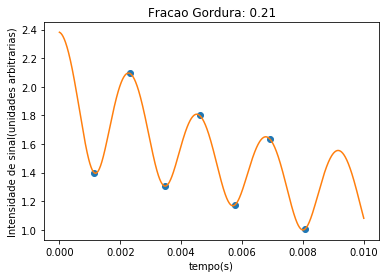

parametro dado
0.23
paramatro encontrado
0.825068613706
valores iniciais + np.random.rand()
[10.165378815146584, 3.8630254966034312]
rhos
(array(0.5), array(1.6739130434782608))


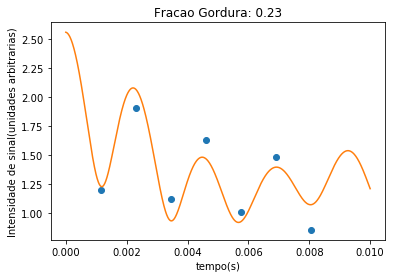

parametro dado
0.25
paramatro encontrado
0.25
valores iniciais + np.random.rand()
[4.5574856046549144, 10.177296618979797]
rhos
(array(0.5), array(1.5))


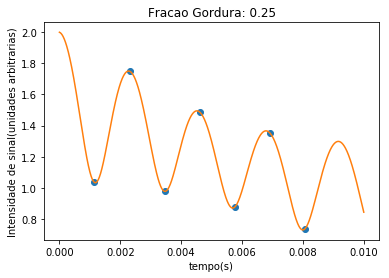

parametro dado
0.27
paramatro encontrado
0.27
valores iniciais + np.random.rand()
[9.0221725060739058, 9.0843969200690786]
rhos
(array(0.5), array(1.3518518518518516))


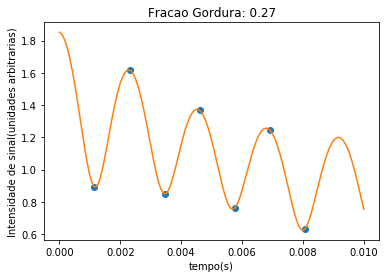

parametro dado
0.29
paramatro encontrado
0.781068134177
valores iniciais + np.random.rand()
[7.6924119318194171, 6.0425374945613406]
rhos
(array(0.5), array(1.2241379310344827))


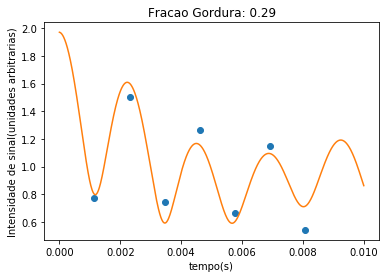

parametro dado
0.31
paramatro encontrado
0.31
valores iniciais + np.random.rand()
[6.9602659651898371, 10.538373308627461]
rhos
(array(0.5), array(1.1129032258064515))


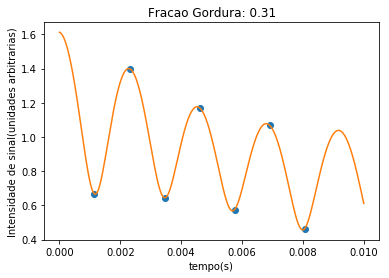

parametro dado
0.33
paramatro encontrado
0.750274114053
valores iniciais + np.random.rand()
[9.5322403586954252, 3.602317633620169]
rhos
(array(0.5), array(1.015151515151515))


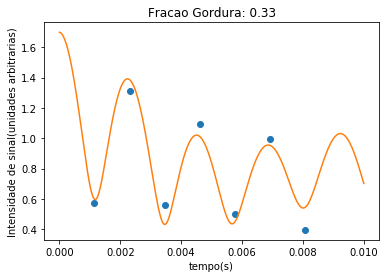

parametro dado
0.35
paramatro encontrado
0.35
valores iniciais + np.random.rand()
[6.0989946456013309, 9.3278452391671571]
rhos
(array(0.5), array(0.9285714285714284))


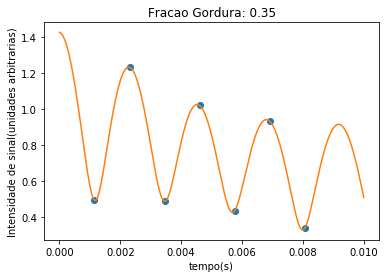

parametro dado
0.37
paramatro encontrado
0.37
valores iniciais + np.random.rand()
[4.3591052361272808, 6.1589283832268595]
rhos
(array(0.5), array(0.8513513513513513))


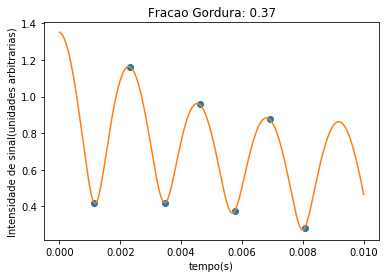

parametro dado
0.39
paramatro encontrado
0.701745062122
valores iniciais + np.random.rand()
[10.125488354820401, 6.6769444970262253]
rhos
(array(0.5), array(0.782051282051282))


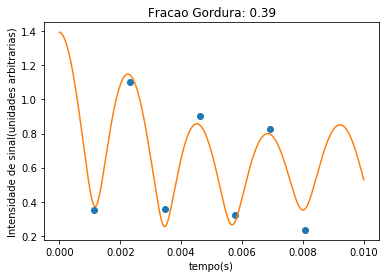

parametro dado
0.41
paramatro encontrado
0.684926781808
valores iniciais + np.random.rand()
[6.9022238544000754, 5.1192957454189978]
rhos
(array(0.5), array(0.7195121951219511))


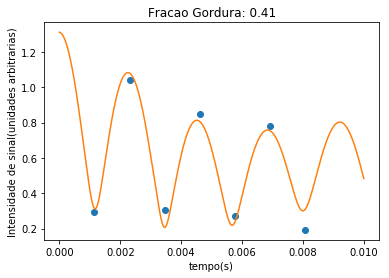

parametro dado
0.43
paramatro encontrado
0.667794272363
valores iniciais + np.random.rand()
[5.5675042118501334, 3.2813329886645146]
rhos
(array(0.5), array(0.6627906976744187))


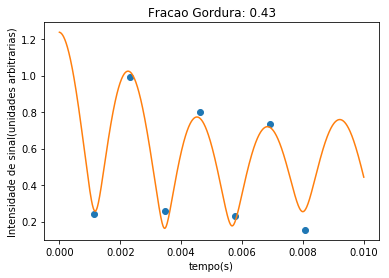

parametro dado
0.45
paramatro encontrado
0.650377012119
valores iniciais + np.random.rand()
[8.5338877876173314, 3.9919393707990314]
rhos
(array(0.5), array(0.6111111111111112))


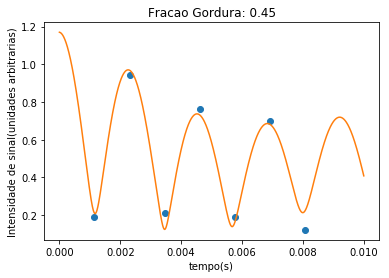

parametro dado
0.47
paramatro encontrado
0.632762146249
valores iniciais + np.random.rand()
[8.9014649578288587, 2.7413939285463651]
rhos
(array(0.5), array(0.5638297872340425))


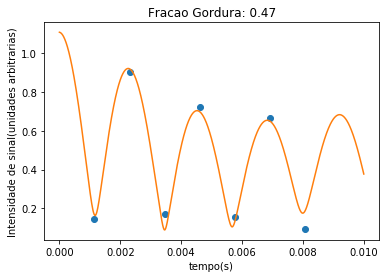

parametro dado
0.49
paramatro encontrado
0.49
valores iniciais + np.random.rand()
[1.9679333003677475, 7.9532191178734726]
rhos
(array(0.5), array(0.5204081632653061))


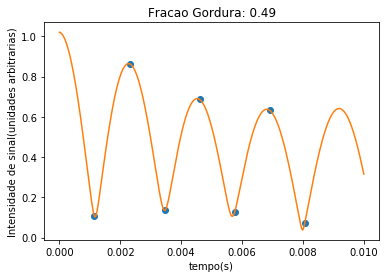

parametro dado
0.51
paramatro encontrado
0.598372035883
valores iniciais + np.random.rand()
[9.8645555132091758, 0.60018805018748844]
rhos
(array(0.5), array(0.48039215686274506))


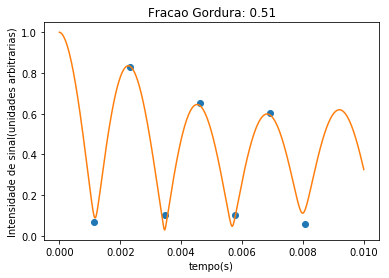

parametro dado
0.53
paramatro encontrado
0.58320422264
valores iniciais + np.random.rand()
[7.1391020497210285, 3.1610343396407816]
rhos
(array(0.5), array(0.4433962264150943))


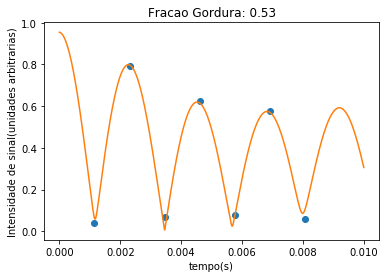

parametro dado
0.55
paramatro encontrado
0.55
valores iniciais + np.random.rand()
[0.92710713103603415, 8.5985200137094946]
rhos
(array(0.5), array(0.409090909090909))


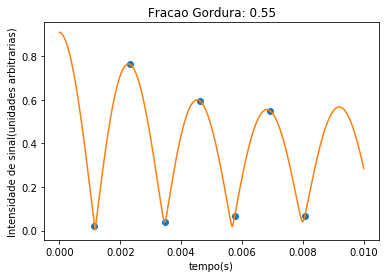

parametro dado
0.57
paramatro encontrado
0.57
valores iniciais + np.random.rand()
[5.4755529155074099, 0.90049865287306496]
rhos
(array(0.5), array(0.37719298245614025))


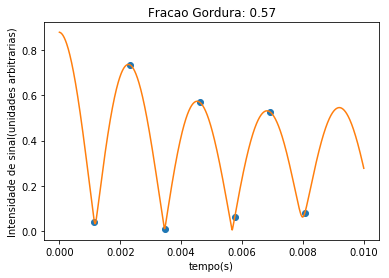

parametro dado
0.59
paramatro encontrado
0.59
valores iniciais + np.random.rand()
[3.8259513380509045, 4.5271931494450977]
rhos
(array(0.5), array(0.3474576271186441))


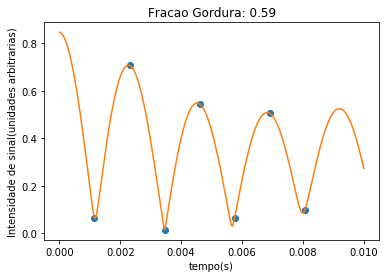

parametro dado
0.61
paramatro encontrado
0.510689564047
valores iniciais + np.random.rand()
[7.1459454912403615, 6.1871835644831368]
rhos
(array(0.5), array(0.319672131147541))


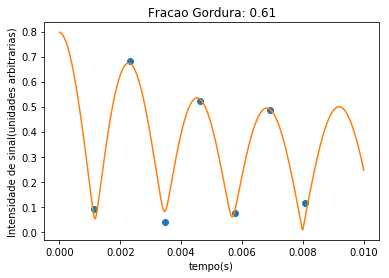

parametro dado
0.63
paramatro encontrado
0.63
valores iniciais + np.random.rand()
[8.526224755431091, 3.0055039218140664]
rhos
(array(0.5), array(0.29365079365079366))


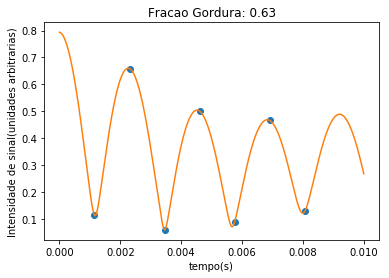

parametro dado
0.65
paramatro encontrado
0.453264414439
valores iniciais + np.random.rand()
[4.5779482625004251, 6.414670944911367]
rhos
(array(0.5), array(0.2692307692307692))


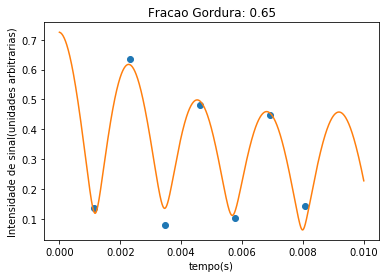

parametro dado
0.67
paramatro encontrado
0.67
valores iniciais + np.random.rand()
[8.1189920965071174, 3.340555204506729]
rhos
(array(0.5), array(0.24626865671641787))


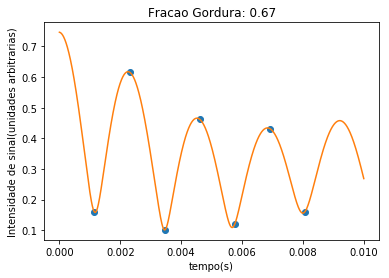

parametro dado
0.69
paramatro encontrado
0.69
valores iniciais + np.random.rand()
[6.4752948805580584, 3.8857615122366669]
rhos
(array(0.5), array(0.22463768115942023))


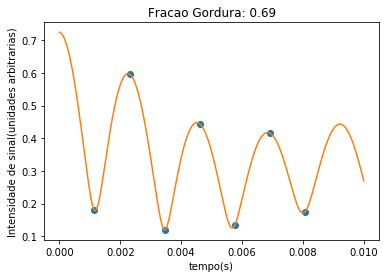

parametro dado
0.71
paramatro encontrado
0.381173665728
valores iniciais + np.random.rand()
[0.50298201328999825, 5.560692683113805]
rhos
(array(0.5), array(0.20422535211267598))


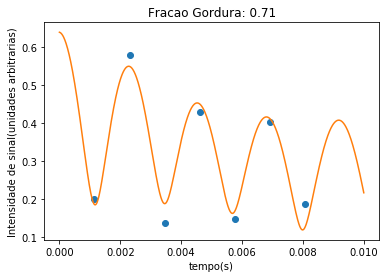

parametro dado
0.73
paramatro encontrado
0.73
valores iniciais + np.random.rand()
[9.2378670020543563, 4.3681090143375725]
rhos
(array(0.5), array(0.18493150684931509))


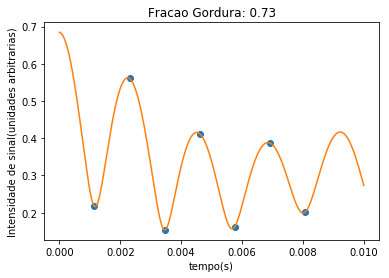

parametro dado
0.75
paramatro encontrado
0.75
valores iniciais + np.random.rand()
[9.9165608993684096, 2.3542737082553504]
rhos
(array(0.5), array(0.16666666666666666))


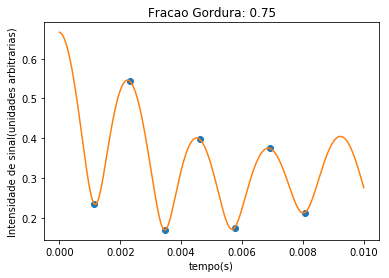

parametro dado
0.77
paramatro encontrado
0.77
valores iniciais + np.random.rand()
[4.3842983135851714, 1.8253977296929893]
rhos
(array(0.5), array(0.14935064935064934))


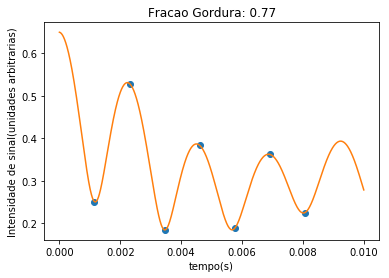

parametro dado
0.79
paramatro encontrado
0.279054244966
valores iniciais + np.random.rand()
[6.6505770409766436, 7.9743947125761725]
rhos
(array(0.5), array(0.13291139240506325))


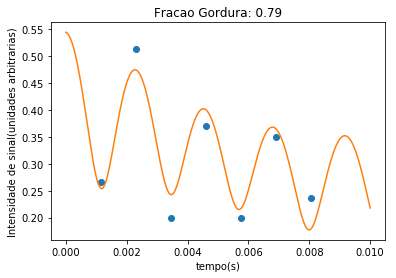

parametro dado
0.81
paramatro encontrado
0.81
valores iniciais + np.random.rand()
[4.47293872856525, 1.3273383919891177]
rhos
(array(0.5), array(0.11728395061728392))


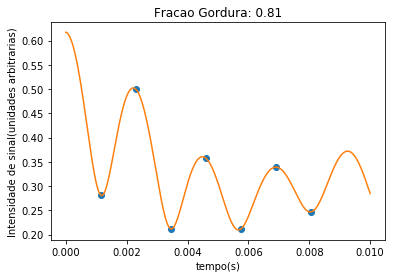

parametro dado
0.83
paramatro encontrado
0.83
valores iniciais + np.random.rand()
[7.6522903474124853, 3.1883781889844314]
rhos
(array(0.5), array(0.10240963855421682))


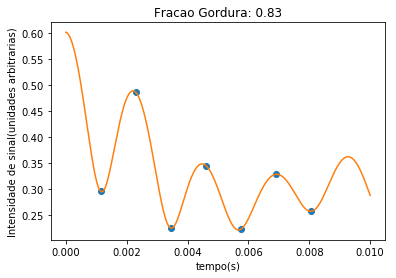

parametro dado
0.85
paramatro encontrado
0.85
valores iniciais + np.random.rand()
[7.2282257931619416, 0.26236204335539448]
rhos
(array(0.5), array(0.08823529411764708))


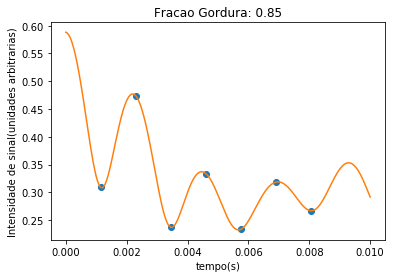

parametro dado
0.87
paramatro encontrado
0.87
valores iniciais + np.random.rand()
[7.2452644280219118, 2.2824432170566253]
rhos
(array(0.5), array(0.07471264367816093))


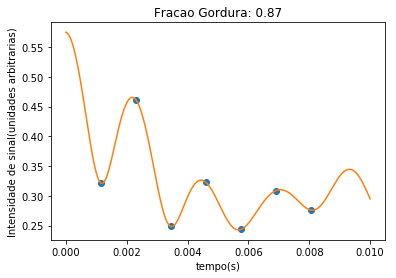

parametro dado
0.89
paramatro encontrado
0.135904624619
valores iniciais + np.random.rand()
[2.2351084707154474, 4.0149788278206016]
rhos
(array(0.5), array(0.061797752808988755))


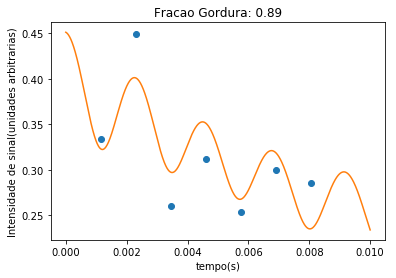

parametro dado
0.91
paramatro encontrado
0.91
valores iniciais + np.random.rand()
[5.5793170081348915, 1.100689956732064]
rhos
(array(0.5), array(0.049450549450549434))


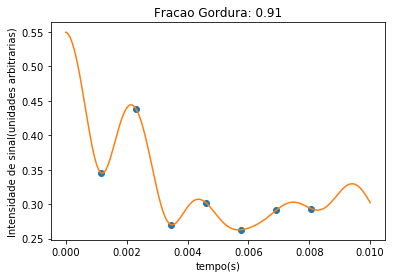

parametro dado
0.93
paramatro encontrado
0.0729150092826
valores iniciais + np.random.rand()
[7.2441893753730113, 9.1695436865777697]
rhos
(array(0.5), array(0.03763440860215051))


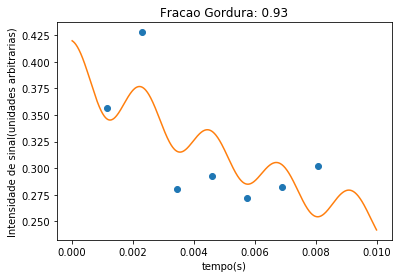

parametro dado
0.95
paramatro encontrado
0.95
valores iniciais + np.random.rand()
[7.2651843262976632, 2.5417936972318529]
rhos
(array(0.5), array(0.026315789473684174))


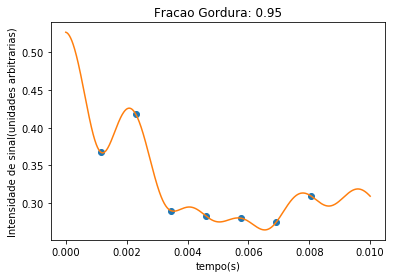

parametro dado
0.97
paramatro encontrado
0.97
valores iniciais + np.random.rand()
[3.8193488492207046, 0.19194663467701162]
rhos
(array(0.5), array(0.01546391752577321))


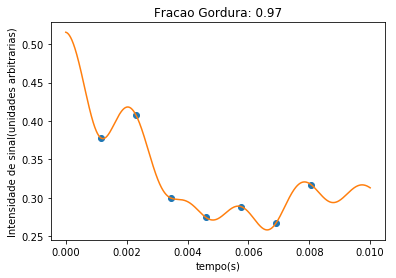

parametro dado
0.99
paramatro encontrado
0.99
valores iniciais + np.random.rand()
[9.9173209531049711, 3.4076936876156525]
rhos
(array(0.5), array(0.005050505050505055))


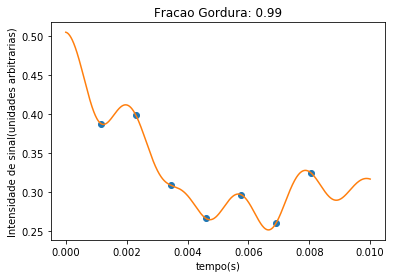

In [22]:
x = continuous_timeseries()
ff = list(np.linspace(0.01,0.99))
fitted_parameter5 = []

for n in ff:
    rho_fat, rho_water = set_rho(n)
    xdata = discrete_timeseries(7)
    ydata = gen_GRE(xdata, rho_fat, rho_water)
    
    p0 = [rho_fat + np.random.rand()*10, rho_water + np.random.rand()*10]
    fitted_par, pcov = curve_fit(gen_GRE, xdata, ydata, p0=p0) # valores iniciais + random em 1.0
    fitted_parameter5.append(fitted_par)
    
    print('parametro dado')
    print(n)
    print('paramatro encontrado')
    print(calc_fatfrac(fitted_par))
    print('valores iniciais + np.random.rand()')
    print(p0)
    print('rhos')
    print(rho_fat, rho_water)
    
    plt.plot(xdata, ydata, 'o')
    plt.plot(x, gen_GRE(x, *fitted_par))
    
    plt.xlabel('tempo(s)')
    plt.ylabel('Intensidade de sinal(unidades arbitrarias)')
    plt.title('Fracao Gordura: {}'.format(n))
    plt.show()

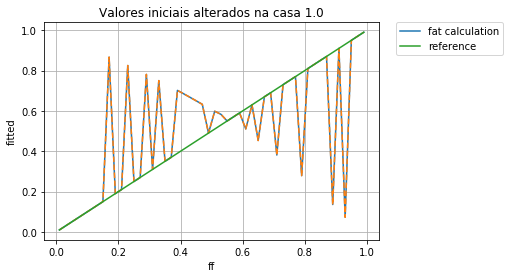

In [24]:
fitted5 = np.array([calc_fatfrac(x) for x in fitted_parameter5])
ff = np.array(ff)

plt.plot(ff, fitted5, '-', label='fat calculation')
plt.plot(ff, fitted5, '--', lw=1.5)
plt.plot(ff, ff, '-', label='reference')

plt.title('Valores iniciais alterados na casa 1.0')
plt.xlabel('ff')
plt.ylabel('fitted')
plt.legend(bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)
plt.grid(True)
plt.show()

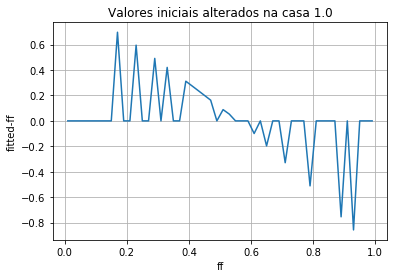

In [25]:
plt.plot(ff, (fitted5-ff), lw=1.5)
plt.title('Valores iniciais alterados na casa 1.0')
plt.xlabel('ff')
plt.ylabel('fitted-ff')
plt.grid(True)
plt.show()

# resumo

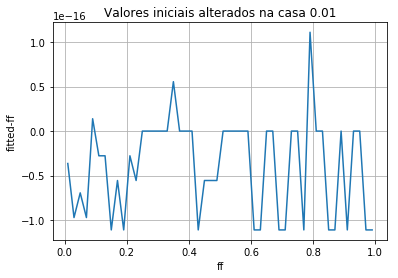

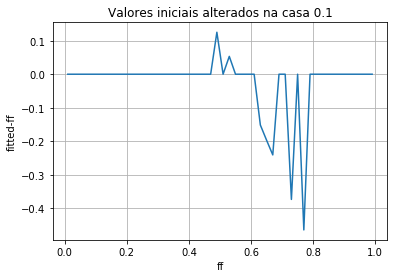

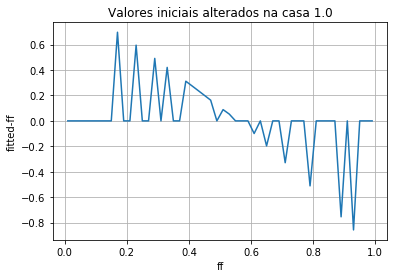

In [26]:
plt.plot(ff, (fitted3-ff), lw=1.5)
plt.title('Valores iniciais alterados na casa 0.01')
plt.xlabel('ff')
plt.ylabel('fitted-ff')
plt.grid(True)
plt.show()

plt.plot(ff, (fitted4-ff), lw=1.5)
plt.title('Valores iniciais alterados na casa 0.1')
plt.xlabel('ff')
plt.ylabel('fitted-ff')
plt.grid(True)
plt.show()

plt.plot(ff, (fitted5-ff), lw=1.5)
plt.title('Valores iniciais alterados na casa 1.0')
plt.xlabel('ff')
plt.ylabel('fitted-ff')
plt.grid(True)
plt.show()